# DocVQA Canonical: Colab Data Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NhanChanDeo/VQA_Final_Thesis/blob/main/ANALYSIS/DocVQA_Analysis.ipynb)

**Dataset:** [`gamusa/docvqa-canonical`](https://huggingface.co/datasets/gamusa/docvqa-canonical): planar 2D document scans (UCSF industry documents) with dense typography, tables and forms; lossless PNG images and Microsoft OCR tokens. **Source domain** of the thesis.

**Plan:** `PLAN/Colab_DocVQA_TextVQA_Analysis_Plan.md` · **Schema:** `CanonicalVQAItem` (`DATASETS SCHEMA NORMALIZATION/canonical_schema.py`)

| Phase | What it answers |
| :--- | :--- |
| 0. Preflight | Does the Colab VM have enough RAM/disk? |
| 1. Fetch | Stream the dataset, reduce every sample to scalar features, and never decode pixels |
| 2. Investigation | Schema, missingness, distributions, integrity, leakage, visual / linguistic / OCR profiles |
| 3. Aggregation | Extractive ceiling, cross-tabs, quartile bucketing, train↔val drift, Pareto concentration |
| 4. Visualization | High-contrast, colour-blind-safe figures (Okabe-Ito + hatching) |
| 5. Evaluation | Data Health Index (0-100), preprocessing checklist, executive summary |

> **Runtime:** standard Colab CPU runtime is enough. With the default cap of 5,000 rows/split the run downloads roughly 1-2 GB.
> Set `MAX_SAMPLES_PER_SPLIT = None` for a full-population profile; RAM stays flat because only scalars are retained.

### ⚠️ Colab Memory (RAM) Bottlenecks & Mitigation Strategies

When working with massive image-based QA datasets such as `DocVQA` (~9 GB) or `TextVQA` (~7 GB) inside free-tier Google Colab instances (which typically offer ~12.7 GB of system RAM), standard ingestion flows will quickly trigger Out-Of-Memory (OOM) crashes.

Here are the primary bottlenecks and how this notebook is designed to avoid them:

1. **Pixel Decoding Overhead (The Biggest Bottleneck)**
   * *Problem:* Fully decoding compressed PNG/JPEG images into raw RGB NumPy arrays in RAM takes up massive memory (e.g., a single 10 MP document page can use up to 30 MB of uncompressed memory).
   * *Mitigation:* We load the dataset using `streaming=True` and cast the `image` column with `decode=False`. This streams raw compressed bytes (`bytes`) instead of decoding pixels. The PIL image parser is called on the byte header only (`im.size`, `im.format`) without loading pixel values.

2. **Large Datasets Cache Accumulation**
   * *Problem:* Standard Hugging Face `load_dataset` downloads and caches the entire dataset onto the local disk or virtual memory partition, leading to disk exhaustion or RAM paging.
   * *Mitigation:* We utilize streaming generators to parse each sample on the fly, process them immediately, and then discard the heavy fields.

3. **Accumulating Non-Scalar Profiles**
   * *Problem:* Appending bounding box coordinate lists `[ymin, xmin, ymax, xmax]` for millions of OCR tokens directly to a Pandas DataFrame will consume gigabytes of memory.
   * *Mitigation:* We accumulate OCR coordinate metrics on-the-fly into a fixed-size $50 \times 50$ spatial density grid (`np.histogram2d`). This maps millions of OCR coordinates to a static array size, keeping memory consumption completely flat regardless of how many rows are streamed.

# 0. Colab Environment Diagnostics & RAM Preflight

In [1]:
# 0.1 Configuration: every tunable knob lives in this cell
import os, sys
from pathlib import Path

DATASETS = {
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "revision": "86e379d727ab104301e3639b909bfbddb0af6376",   # pinned `main` (train + validation)
        "label": "DocVQA",
        "color": "#0072B2",   # Okabe-Ito blue
        "hatch": "//",
        "marker": "o",
    },
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "revision": "d1dcf73eda54e82e84f69d0265f3a9e663420583",   # pinned `main` (train + validation)
        "label": "TextVQA",
        "color": "#D55E00",   # Okabe-Ito vermilion
        "hatch": "xx",
        "marker": "X",
    },
}
SPLITS = ["train", "validation"]

# Sampling: 5,000 rows per split for interactive use. Set to None to profile the full split
# (streams ~9 GB for DocVQA / ~7 GB for TextVQA; RAM stays flat because only scalars are kept).
_cap = os.environ.get("CROSSVQA_MAX_SAMPLES", "5000")
MAX_SAMPLES_PER_SPLIT = None if _cap.lower() in ("0", "", "none") else int(_cap)
SHUFFLE_BUFFER = int(os.environ.get("CROSSVQA_SHUFFLE_BUFFER", "256"))   # rows held in RAM for shuffling
SEED = 42

RAM_FLOOR_GB = 2.5            # gc.collect() + warning below this much available RAM
GALLERY_SIZE = 6              # sample images kept (raw bytes) for the visual gallery
HIST_BINS = 50                # resolution of the OCR box-centre density grid
BOX_SAMPLE_CAP = 200_000      # max individual boxes kept for box-level distributions
BOXES_PER_IMAGE_SAMPLE = 25
ENCODER_RESOLUTIONS = [224, 336, 448, 896, 1344]   # longest-side input sizes of common VLM encoders
LEGIBILITY_PX = 8             # rough minimum glyph height (px) for a ViT patch grid to resolve text

USE_GOOGLE_DRIVE = False      # True -> persist reports to Drive so other notebooks can reuse the cache
IN_COLAB = "google.colab" in sys.modules
OUTPUT_DIR = Path("reports")
if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/CrossVQA_Analysis/reports")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATASET_KEY = "docvqa"
CFG = DATASETS[DATASET_KEY]
REUSE_CACHE = False           # True -> load reports/docvqa_profile.parquet instead of re-streaming
print(f"Dataset: {CFG['repo_id']} @ {CFG['revision'][:10]} | splits={SPLITS} | "
      f"cap/split={MAX_SAMPLES_PER_SPLIT or 'FULL'} | output={OUTPUT_DIR} | Colab={IN_COLAB}")

Dataset: gamusa/docvqa-canonical @ 86e379d727 | splits=['train', 'validation'] | cap/split=5000 | output=reports | Colab=True


In [2]:
# 0.2 Dependencies: only `datasets` / `huggingface_hub` are upgraded on Colab (everything else is preinstalled).
import subprocess
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "datasets>=3.0", "huggingface_hub"], check=True)
    print("Upgraded: datasets, huggingface_hub")
else:
    print("Not running on Colab: using the active environment as-is.")

Upgraded: datasets, huggingface_hub


In [3]:
# 0.3 Imports, accessible plotting style, Hugging Face auth
import gc, io, re, json, math, time, random, hashlib, shutil, platform, textwrap, warnings
from collections import Counter
from datetime import datetime

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
import seaborn as sns
from scipy import stats
from scipy.spatial.distance import jensenshannon
from PIL import Image as PILImage, ImageOps
from tqdm.auto import tqdm
from IPython.display import display, Markdown
import plotly.express as px
import datasets
from datasets import load_dataset, load_dataset_builder, Image as HFImage
from huggingface_hub import HfApi

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
PILImage.MAX_IMAGE_PIXELS = None   # large document scans are legitimate, not decompression bombs

# Okabe-Ito colour-blind-safe palette; black is reserved for edges/text.
OKABE_ITO = {"blue": "#0072B2", "vermilion": "#D55E00", "green": "#009E73", "orange": "#E69F00",
             "sky": "#56B4E9", "purple": "#CC79A7", "yellow": "#F0E442", "grey": "#999999"}
PALETTE = [OKABE_ITO[k] for k in ("blue", "vermilion", "green", "orange", "sky", "purple", "yellow")]
HATCHES = ["//", "xx", "..", "++", "\\\\", "oo", "--", "**"]
SEQ_CMAP = sns.color_palette("mako", as_cmap=True)
DIV_CMAP = sns.color_palette("vlag", as_cmap=True)

plt.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 150, "font.size": 10.5,
    "axes.titleweight": "bold", "axes.labelweight": "bold", "axes.titlesize": 12,
    "axes.edgecolor": "#222222", "axes.linewidth": 1.1, "axes.grid": True, "grid.alpha": 0.25,
    "legend.frameon": True, "legend.framealpha": 0.92, "hatch.linewidth": 0.8,
})
sns.set_palette(PALETTE)

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print(f"[saved] {path}")

HF_TOKEN = os.environ.get("HF_TOKEN")
if IN_COLAB and not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")   # optional Colab secret; datasets are public
    except Exception:
        HF_TOKEN = None
print(f"datasets {datasets.__version__} | pandas {pd.__version__} | numpy {np.__version__} | HF token: {'yes' if HF_TOKEN else 'no (public access)'}")

datasets 5.1.0 | pandas 2.2.3 | numpy 2.1.3 | HF token: yes


In [4]:
# 0.4 Runtime diagnostics & RAM guard
vm, disk = psutil.virtual_memory(), shutil.disk_usage("/")
try:
    import torch
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
except Exception:
    gpu = "torch not installed"

print("=" * 66)
print("COLAB RUNTIME DIAGNOSTICS")
print("=" * 66)
print(f"Platform   : {platform.system()} {platform.release()} | Python {sys.version.split()[0]}")
print(f"CPU cores  : {psutil.cpu_count(logical=False)} physical / {psutil.cpu_count(logical=True)} logical")
print(f"RAM        : {vm.total/1024**3:.2f} GB total | {vm.available/1024**3:.2f} GB available")
print(f"Disk       : {disk.total/1024**3:.1f} GB total | {disk.free/1024**3:.1f} GB free")
print(f"GPU        : {gpu} (not required: this analysis is CPU/IO-bound)")
print("=" * 66)

def mem_guard(tag=""):
    avail = psutil.virtual_memory().available / 1024**3
    if avail < RAM_FLOOR_GB:
        gc.collect()
        avail = psutil.virtual_memory().available / 1024**3
        print(f"[RAM WARNING] {tag}: only {avail:.2f} GB available after gc.collect()")
    return avail

print("[STATUS] RAM headroom OK" if vm.available / 1024**3 >= RAM_FLOOR_GB
      else "[WARNING] Low RAM: keep MAX_SAMPLES_PER_SPLIT small and SHUFFLE_BUFFER low")

COLAB RUNTIME DIAGNOSTICS
Platform   : Linux 6.6.122+ | Python 3.13.16
CPU cores  : 1 physical / 2 logical
RAM        : 12.67 GB total | 5.09 GB available
Disk       : 225.8 GB total | 205.1 GB free
GPU        : none (not required: this analysis is CPU/IO-bound)
[STATUS] RAM headroom OK


# 1. Fetch: Universal Ingestion & Normalization

Rows are streamed (`streaming=True`) with the image column cast to `decode=False`, so each image arrives as raw bytes.
PIL reads only the **header** (size, format, mode, EXIF) and the bytes are hashed for leakage checks. Each sample is
then reduced to ~50 scalar features covering three modalities:

* **Visual:** probed vs declared size, megapixels, aspect ratio, format, EXIF orientation, byte size
* **Linguistic:** question length and starter, answer length/type, annotator agreement and entropy
* **OCR / spatial:** token count, extractive class of the answer, box area and coverage, glyph height in px, reading-order consistency.
  Box centres are accumulated into a 50×50 density grid instead of being stored.

In [5]:
# 1.1 Row-level profiling primitives. Each sample is reduced to scalars; pixel buffers are never decoded.
_PUNCT_RE = re.compile(r"[^\w\s]")
_WS_RE = re.compile(r"\s+")
_NUMERIC_RE = re.compile(r"^[\d\s.,:/\-%$€£¥+()#]+$")

def norm_text(s):
    # Lower-case, strip punctuation, collapse whitespace (VQA-style normalisation).
    if s is None:
        return ""
    return _WS_RE.sub(" ", _PUNCT_RE.sub(" ", str(s).lower())).strip()

_STARTER_RULES = [(label, re.compile(p)) for label, p in [
    ("how many", r"^how many\b"), ("how much", r"^how much\b"), ("what", r"^what\b"),
    ("which", r"^which\b"), ("who/whose", r"^(who|whose|whom)\b"), ("where", r"^where\b"),
    ("when", r"^when\b"), ("why", r"^why\b"), ("how (other)", r"^how\b"),
    ("yes/no (aux verb)", r"^(is|are|was|were|do|does|did|can|could|will|would|has|have|had|should)\b"),
    ("imperative (name/give)", r"^(name|give|mention|write|list|state|tell)\b"),
]]
_EMBEDDED_WH = re.compile(r"\b(what|which|who|whose|where|when|why|how)\b")

def question_starter(q):
    qn = norm_text(q)
    for label, pat in _STARTER_RULES:
        if pat.search(qn):
            return label
    return "embedded wh-word" if _EMBEDDED_WH.search(qn) else "other"

def answer_type(a):
    if a is None or not str(a).strip():
        return "missing"
    s = str(a).strip().lower()
    if s in {"yes", "no"}:
        return "yes/no"
    has_d, has_a = any(c.isdigit() for c in s), any(c.isalpha() for c in s)
    if has_d and _NUMERIC_RE.match(s):
        return "numeric/date/amount"
    if has_d and has_a:
        return "alphanumeric"
    if has_a:
        return "alphabetic"
    return "symbolic/other"

EXTRACTIVE_OK = {"exact_token", "contiguous_span"}

def build_ocr_index(tokens):
    toks = [t for t in (norm_text(t) for t in tokens) if t]
    return set(toks), " " + " ".join(toks) + " "

def extractive_class(answer, idx, has_ocr):
    # Where does the answer live relative to the OCR candidate pool?
    if not has_ocr:
        return "no_ocr"
    a = norm_text(answer)
    if not a:
        return "no_answer"
    tokset, joined = idx
    if a in tokset:
        return "exact_token"
    if f" {a} " in joined:
        return "contiguous_span"
    if all(w in tokset for w in a.split()):
        return "scattered_tokens"
    return "not_in_ocr"

def answer_agreement(answers, canonical):
    clean = [a for a in (norm_text(x) for x in answers) if a]
    if not clean:
        return np.nan, np.nan, 0, np.nan
    counts, n = Counter(clean), len(clean)
    probs = np.array(list(counts.values()), dtype=float) / n
    agreement = counts.most_common(1)[0][1] / n
    entropy = float(-(probs * np.log2(probs)).sum())
    vqa_acc = min(counts.get(norm_text(canonical), 0) / 3.0, 1.0)   # min(#humans/3, 1)
    return agreement, entropy, len(counts), vqa_acc

def probe_image(field):
    # Header-only probe: PIL reads size/format/mode/EXIF without decoding pixels.
    out = {"probe_width": None, "probe_height": None, "image_format": None, "image_mode": None,
           "exif_orientation": 1, "byte_size": 0, "image_md5": None, "image_corrupt": True}
    raw = field.get("bytes") if isinstance(field, dict) else None
    if not raw:
        return out
    out["byte_size"] = len(raw)
    out["image_md5"] = hashlib.md5(raw).hexdigest()
    try:
        with PILImage.open(io.BytesIO(raw)) as im:
            out["probe_width"], out["probe_height"] = im.size
            out["image_format"], out["image_mode"] = im.format, im.mode
            try:
                out["exif_orientation"] = int(im.getexif().get(0x0112, 1) or 1)
            except Exception:
                pass
        out["image_corrupt"] = False
    except Exception:
        pass
    return out

_rng = random.Random(SEED)

def spatial_features(boxes, img_h, acc):
    # Boxes follow CanonicalVQAItem: [ymin, xmin, ymax, xmax] normalised to [0, 1000].
    boxes = list(boxes or [])
    out = {"n_boxes": len(boxes), "invalid_boxes": 0, "box_area_median": np.nan, "text_coverage": np.nan,
           "box_h_px_median": np.nan, "reading_order_consistency": np.nan}
    valid = [b for b in boxes if b is not None and len(b) == 4]
    out["invalid_boxes"] = len(boxes) - len(valid)
    if not valid:
        return out
    arr = np.asarray(valid, dtype=np.float32)
    ymin, xmin, ymax, xmax = arr[:, 0], arr[:, 1], arr[:, 2], arr[:, 3]
    bad = ((arr < 0) | (arr > 1000)).any(axis=1) | (ymax < ymin) | (xmax < xmin)
    out["invalid_boxes"] += int(bad.sum())
    h, w = np.clip(ymax - ymin, 0, 1000), np.clip(xmax - xmin, 0, 1000)
    area = h * w / 1e6
    out["box_area_median"] = float(np.median(area))
    out["text_coverage"] = float(min(area.sum(), 1.0))          # sum of box areas, capped (overlaps ignored)
    yc, xc = np.clip((ymin + ymax) / 2, 0, 1000), np.clip((xmin + xmax) / 2, 0, 1000)
    acc["hist"] += np.histogram2d(yc, xc, bins=HIST_BINS, range=[[0, 1000], [0, 1000]])[0]
    h_px = h / 1000.0 * img_h if img_h else None
    if h_px is not None:
        out["box_h_px_median"] = float(np.median(h_px))
    if len(arr) >= 3:
        # Fraction of consecutive OCR tokens that follow left-to-right / top-to-bottom reading order.
        tol = 0.5 * max(float(np.median(h)), 1.0)
        dy, dx = np.diff(yc), np.diff(xc)
        out["reading_order_consistency"] = float(np.where(np.abs(dy) < tol, dx > 0, dy > 0).mean())
    if len(acc["box_area"]) < BOX_SAMPLE_CAP:
        idx = _rng.sample(range(len(area)), min(BOXES_PER_IMAGE_SAMPLE, len(area)))
        acc["box_area"].extend(area[idx].tolist())
        if h_px is not None:
            acc["box_h_px"].extend(h_px[idx].tolist())
    return out

def parse_metadata(meta_str):
    # `metadata` is a JSON string; keep short scalars and list-of-strings (e.g. question types, image classes).
    if not meta_str:
        return {}, []
    try:
        d = json.loads(meta_str)
    except Exception:
        return {"meta__unparseable": True}, []
    if not isinstance(d, dict):
        return {}, []
    out = {}
    for k, v in d.items():
        if isinstance(v, list) and v and all(isinstance(x, str) for x in v):
            out[f"meta__{k}"] = "|".join(v)
        elif isinstance(v, (int, float, bool)) or (isinstance(v, str) and len(v) <= 80):
            out[f"meta__{k}"] = v
    return out, list(d.keys())

def new_accumulator():
    return {"hist": np.zeros((HIST_BINS, HIST_BINS)), "box_area": [], "box_h_px": [],
            "meta_keys": Counter(), "gallery": []}

def profile_row(row, acc):
    q = row.get("question") or ""
    rec = {"sample_id": row.get("sample_id"), "domain_type": row.get("domain_type"), "split": row.get("split"),
           "question_id": None if row.get("question_id") is None else str(row["question_id"]),
           "image_id": row.get("image_id"), "question": q, "question_norm": norm_text(q),
           "question_len_chars": len(q),
           "question_len_tokens": len(row.get("question_tokens") or norm_text(q).split()),
           "question_starter": question_starter(q)}
    # Visual modality
    img = probe_image(row.get("image"))
    rec.update(img)
    W, H = row.get("image_width"), row.get("image_height")
    rec["image_width"], rec["image_height"] = W, H
    rec["dims_consistent"] = bool(img["probe_width"] is not None and W == img["probe_width"] and H == img["probe_height"])
    w_eff, h_eff = img["probe_width"] or W, img["probe_height"] or H
    ok = bool(w_eff and h_eff)
    rec["aspect_ratio"] = w_eff / h_eff if ok else np.nan
    rec["megapixels"] = w_eff * h_eff / 1e6 if ok else np.nan
    rec["long_side_px"] = max(w_eff, h_eff) if ok else np.nan
    # Linguistic modality (labels)
    answers = list(row.get("answers") or [])
    canon = row.get("canonical_answer")
    rec["answers_count"] = len(answers)
    rec["canonical_answer"] = canon
    rec["answer_norm"] = norm_text(canon)
    rec["answer_len_chars"] = len(str(canon)) if canon else np.nan
    rec["answer_len_tokens"] = len(norm_text(canon).split()) if canon else np.nan
    rec["answer_type"] = answer_type(canon)
    (rec["answer_agreement"], rec["answer_entropy"],
     rec["answer_unique_variants"], rec["canonical_vqa_acc"]) = answer_agreement(answers, canon)
    # OCR / spatial modality
    ocr_tokens = list(row.get("ocr_tokens") or [])
    has_ocr = len(ocr_tokens) > 0
    idx = build_ocr_index(ocr_tokens) if has_ocr else (set(), " ")
    rec["ocr_token_count"] = len(ocr_tokens)
    rec["extractive_class"] = extractive_class(canon, idx, has_ocr)
    rec["any_answer_in_ocr"] = bool(has_ocr and any(extractive_class(a, idx, True) in EXTRACTIVE_OK for a in set(answers)))
    rec.update(spatial_features(row.get("ocr_boxes"), h_eff, acc))
    rec["ocr_box_token_mismatch"] = rec["n_boxes"] != len(ocr_tokens)
    # Domain-specific metadata
    meta, keys = parse_metadata(row.get("metadata"))
    acc["meta_keys"].update(keys)
    rec.update(meta)
    if len(acc["gallery"]) < GALLERY_SIZE and img["byte_size"] and not img["image_corrupt"]:
        acc["gallery"].append({"bytes": row["image"]["bytes"], "question": q, "answer": canon,
                               "boxes": [list(b) for b in (row.get("ocr_boxes") or [])[:400]]})
    return rec

In [6]:
# 1.2 Streaming ingestion, normalisation, downcasting, caching
def resolve_revision(repo_id, pinned):
    api = HfApi(token=HF_TOKEN)
    try:
        return api.dataset_info(repo_id, revision=pinned).sha
    except Exception as e:
        print(f"[WARN] pinned revision {pinned[:10]} unavailable for {repo_id} ({type(e).__name__}); using 'main'")
        return api.dataset_info(repo_id, revision="main").sha

def split_size(repo_id, revision, split):
    try:
        return load_dataset_builder(repo_id, revision=revision, token=HF_TOKEN).info.splits[split].num_examples
    except Exception:
        return None

def profile_split(repo_id, revision, split, acc, max_samples, declared):
    ds = load_dataset(repo_id, split=split, revision=revision, streaming=True, token=HF_TOKEN)
    ds = ds.cast_column("image", HFImage(decode=False))       # raw bytes only: zero-OOM probing
    if SHUFFLE_BUFFER:
        ds = ds.shuffle(seed=SEED, buffer_size=SHUFFLE_BUFFER)  # shuffles shard order + a small row buffer
    total = declared
    if max_samples:
        ds = ds.take(max_samples)
        total = min(declared or max_samples, max_samples)
    rows = []
    for i, row in enumerate(tqdm(ds, total=total, desc=f"{repo_id.split('/')[-1]}:{split}")):
        rec = profile_row(row, acc)
        rec["split_requested"] = split
        rows.append(rec)
        if i % 1000 == 0:
            mem_guard(f"{split}@{i}")
    return rows

def finalize_profile(df):
    df = df.copy()
    df["width_px"] = df["probe_width"].fillna(df["image_width"]).astype(float)
    df["height_px"] = df["probe_height"].fillna(df["image_height"]).astype(float)
    df["aspect_bucket"] = pd.cut(df["aspect_ratio"], bins=[0, 0.8, 1.25, np.inf],
                                 labels=["portrait (<0.8)", "square (0.8-1.25)", "landscape (>1.25)"]).astype(str)
    for R in ENCODER_RESOLUTIONS:
        # Median OCR glyph height after resizing the longest image side to R px (aspect-preserving resize).
        df[f"glyph_px_at_{R}"] = df["box_h_px_median"] * R / df["long_side_px"]
    df["ocr_tokens_plus1"] = df["ocr_token_count"] + 1
    for c in [c for c in df.columns if c.startswith("meta__")]:
        df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and math.isnan(v)) else str(v))
    return df

KEEP_AS_TEXT = {"sample_id", "question_id", "image_id", "question", "question_norm",
                "canonical_answer", "answer_norm", "image_md5"}

def downcast(df):
    before = df.memory_usage(deep=True).sum()
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_integer_dtype(s):
            df[c] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_float_dtype(s):
            df[c] = pd.to_numeric(s, downcast="float")
        elif s.dtype == object and c not in KEEP_AS_TEXT and s.nunique(dropna=True) <= max(50, 0.05 * len(s)):
            df[c] = s.astype("category")
    after = df.memory_usage(deep=True).sum()
    print(f"[downcast] {before/1024**2:.2f} MB -> {after/1024**2:.2f} MB ({1 - after/max(before, 1):.0%} saved)")
    return df

def save_profile(key, df, acc, meta):
    df.to_parquet(OUTPUT_DIR / f"{key}_profile.parquet", index=False, compression="zstd")
    np.save(OUTPUT_DIR / f"{key}_spatial_hist.npy", acc["hist"])
    np.savez_compressed(OUTPUT_DIR / f"{key}_box_samples.npz",
                        box_area=np.asarray(acc["box_area"], dtype=np.float32),
                        box_h_px=np.asarray(acc["box_h_px"], dtype=np.float32))
    (OUTPUT_DIR / f"{key}_run_meta.json").write_text(json.dumps(meta, indent=2, default=str))
    print(f"[cache] profile + spatial grid + box samples written to {OUTPUT_DIR}/{key}_*")

def profile_dataset(key, max_samples=MAX_SAMPLES_PER_SPLIT):
    cfg = DATASETS[key]
    rev = resolve_revision(cfg["repo_id"], cfg["revision"])
    acc, rows, sizes, t0 = new_accumulator(), [], {}, time.time()
    for split in SPLITS:
        sizes[split] = split_size(cfg["repo_id"], rev, split)
        rows.extend(profile_split(cfg["repo_id"], rev, split, acc, max_samples, sizes[split]))
        mem_guard(f"after {split}")
    df = downcast(finalize_profile(pd.DataFrame(rows)))
    del rows
    gc.collect()
    meta = {"dataset_key": key, "repo_id": cfg["repo_id"], "revision_requested": cfg["revision"],
            "revision_resolved": rev, "splits": SPLITS, "split_sizes": sizes,
            "max_samples_per_split": max_samples,
            "sampled": bool(max_samples and any((s is None) or (s > max_samples) for s in sizes.values())),
            "rows_profiled": len(df), "seconds": round(time.time() - t0, 1),
            "metadata_keys": dict(acc["meta_keys"].most_common()),
            "created": datetime.now().isoformat(timespec="seconds")}
    save_profile(key, df, acc, meta)
    return df, acc, meta

def load_or_profile(key, reuse=True):
    p = OUTPUT_DIR / f"{key}_profile.parquet"
    if reuse and p.exists():
        df = pd.read_parquet(p)
        acc = new_accumulator()
        acc["hist"] = np.load(OUTPUT_DIR / f"{key}_spatial_hist.npy")
        z = np.load(OUTPUT_DIR / f"{key}_box_samples.npz")
        acc["box_area"], acc["box_h_px"] = z["box_area"].tolist(), z["box_h_px"].tolist()
        meta = json.loads((OUTPUT_DIR / f"{key}_run_meta.json").read_text())
        print(f"[cache] loaded {len(df):,} rows for {key} (created {meta.get('created')})")
        return df, acc, meta
    return profile_dataset(key)

In [7]:
# 1.3 Run ingestion (or reuse cache)
df, ACC, RUN_META = load_or_profile(DATASET_KEY, reuse=REUSE_CACHE)
print(json.dumps({k: v for k, v in RUN_META.items() if k != "metadata_keys"}, indent=2, default=str))
print("metadata JSON keys:", RUN_META.get("metadata_keys"))
mem_guard("after ingestion")

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

docvqa-canonical:validation:   0%|          | 0/5000 [00:00<?, ?it/s]

[downcast] 15.04 MB -> 7.55 MB (50% saved)
[cache] profile + spatial grid + box samples written to reports/docvqa_*
{
  "dataset_key": "docvqa",
  "repo_id": "gamusa/docvqa-canonical",
  "revision_requested": "86e379d727ab104301e3639b909bfbddb0af6376",
  "revision_resolved": "86e379d727ab104301e3639b909bfbddb0af6376",
  "splits": [
    "train",
    "validation"
  ],
  "split_sizes": {
    "train": null,
    "validation": null
  },
  "max_samples_per_split": 5000,
  "sampled": true,
  "rows_profiled": 10000,
  "seconds": 417.7,
  "created": "2026-10-11T17:53:20"
}
metadata JSON keys: {'question_types': 10000, 'docId': 10000, 'ucsf_document_id': 10000, 'ucsf_document_page_no': 10000}


8.803630828857422

# 2. Investigation: Schema Profiling & Diagnostics

In [8]:
# 2.0 Diagnostic helpers (semantic typing, integrity audit)
def semantic_type(s):
    n = int(s.notna().sum())
    if n == 0:
        return "empty"
    nun = s.nunique(dropna=True)
    if nun <= 1:
        return "constant"
    if pd.api.types.is_bool_dtype(s) or nun == 2:
        return "boolean"
    if pd.api.types.is_numeric_dtype(s):
        return "numeric_discrete" if pd.api.types.is_integer_dtype(s) and nun <= 20 else "numeric_continuous"
    avg_len = s.dropna().astype(str).str.len().mean()
    if nun / n > 0.95:
        return "text" if avg_len > 30 else "id_identifier"
    if nun <= 20:
        return "categorical_low"
    return "text" if avg_len > 30 else "categorical_high"

def compute_integrity(df):
    S = lambda c: df[c].astype(str)
    tr, va = S("split_requested") == "train", S("split_requested") == "validation"
    pair = S("image_md5") + "||" + S("question_norm")
    core = ["question", "canonical_answer", "image_md5", "image_width", "image_height"]
    total_boxes = float(df["n_boxes"].sum())
    integ = {
        "rows": len(df),
        "null_rates": {c: float(df[c].isna().mean()) if c in df else 1.0 for c in core},
        "empty_question_rate": float((df["question"].fillna("").astype(str).str.strip() == "").mean()),
        "missing_answer_rate": float((df["answers_count"] == 0).mean()),
        "corrupt_image_rate": float(df["image_corrupt"].astype(bool).mean()),
        "dims_mismatch_rate": float((~df["dims_consistent"].astype(bool)).mean()),
        "split_label_mismatch_rate": float((S("split") != S("split_requested")).mean()),
        "dup_sample_id_rate": float(df["sample_id"].duplicated().mean()),
        "dup_pair_rate": float(pair.duplicated().mean()),
        "image_leak_rate": np.nan, "pair_leak_rate": np.nan, "question_overlap_rate": np.nan,
        "ocr_available_rate": float((df["ocr_token_count"] > 0).mean()),
        "invalid_box_rate": float(df["invalid_boxes"].sum() / total_boxes) if total_boxes else 0.0,
        "box_token_mismatch_rate": float(df["ocr_box_token_mismatch"].astype(bool).mean()),
        "exif_rotated_rate": float((df["exif_orientation"].fillna(1) != 1).mean()),
    }
    if tr.any() and va.any():
        integ["image_leak_rate"] = float(df.loc[va, "image_md5"].isin(set(df.loc[tr, "image_md5"].dropna())).mean())
        integ["pair_leak_rate"] = float(pair[va].isin(set(pair[tr])).mean())
        integ["question_overlap_rate"] = float(df.loc[va, "question_norm"].isin(set(df.loc[tr, "question_norm"])).mean())
    return integ

def answer_concentration(df):
    counts = df["answer_norm"].replace("", np.nan).dropna().astype(str).value_counts()
    if counts.empty:
        return {"unique_answers": 0, "top1_share": np.nan, "norm_entropy": np.nan, "n_for_50pct": 0, "n_for_80pct": 0, "counts": counts}
    p = counts / counts.sum()
    cum = p.cumsum().values
    return {"unique_answers": int(len(counts)), "top1_share": float(p.iloc[0]), "top1_answer": counts.index[0],
            "norm_entropy": float(-(p * np.log2(p)).sum() / np.log2(len(p))) if len(p) > 1 else 0.0,
            "n_for_50pct": int(np.searchsorted(cum, 0.5) + 1), "n_for_80pct": int(np.searchsorted(cum, 0.8) + 1),
            "counts": counts}

In [9]:
# 2.1 Schema overview & semantic typing
print(f"Rows profiled: {len(df):,} | columns: {df.shape[1]} | in-memory: {df.memory_usage(deep=True).sum()/1024**2:.1f} MB")
split_tbl = df["split_requested"].astype(str).value_counts().rename("profiled").to_frame()
split_tbl["declared"] = [RUN_META["split_sizes"].get(s) for s in split_tbl.index]
split_tbl["coverage_%"] = 100 * split_tbl["profiled"] / split_tbl["declared"].astype(float)
display(split_tbl)
schema = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
                       "null_%": (df.isna().mean() * 100).round(2), "n_unique": df.nunique(dropna=True),
                       "semantic_type": [semantic_type(df[c]) for c in df.columns]})
display(schema)
display(df.drop(columns=["question_norm", "answer_norm"]).head(3))

Rows profiled: 10,000 | columns: 58 | in-memory: 7.6 MB


,profiled,declared,coverage_%
split_requested,,,
train,5000,None,NaN
validation,5000,None,NaN


,dtype,non_null,null_%,n_unique,semantic_type
sample_id,object,10000,0.0000,10000,id_identifier
domain_type,category,10000,0.0000,1,constant
split,category,10000,0.0000,2,boolean
question_id,object,10000,0.0000,10000,id_identifier
image_id,object,10000,0.0000,2616,categorical_high
question,object,10000,0.0000,8443,text
question_norm,object,10000,0.0000,8016,text
question_len_chars,int16,10000,0.0000,125,numeric_continuous
question_len_tokens,int8,10000,0.0000,23,numeric_continuous
question_starter,category,10000,0.0000,13,categorical_low


,sample_id,domain_type,split,question_id,image_id,question,question_len_chars,question_len_tokens,question_starter,probe_width,probe_height,image_format,image_mode,exif_orientation,byte_size,image_md5,image_corrupt,image_width,image_height,dims_consistent,aspect_ratio,megapixels,long_side_px,answers_count,canonical_answer,answer_len_chars,answer_len_tokens,answer_type,answer_agreement,answer_entropy,answer_unique_variants,canonical_vqa_acc,ocr_token_count,extractive_class,any_answer_in_ocr,n_boxes,invalid_boxes,box_area_median,text_coverage,box_h_px_median,reading_order_consistency,ocr_box_token_mismatch,meta__question_types,meta__docId,meta__ucsf_document_id,meta__ucsf_document_page_no,split_requested,width_px,height_px,aspect_bucket,glyph_px_at_224,glyph_px_at_336,glyph_px_at_448,glyph_px_at_896,glyph_px_at_1344,ocr_tokens_plus1
0,docvqa_41596,document_text,train,41596,qjgn0226_77.png,Who is the vendor mentioned in the form?,40,8,who/whose,1706,2201,PNG,L,1,459221,43308408a3bfc442d82ab23c73d0be2c,False,1706,2201,True,0.7751,3.7549,2201,2,"Roger Emerson Jr, MD",20,4,alphabetic,1.0000,-0.0000,1,0.6667,97,not_in_ocr,False,97,0,0.0007,0.0813,30.8140,1.0000,False,form,11798,qjgn0226,77,train,"1,706.0000","2,201.0000",portrait (<0.8),3.1360,4.7040,6.2720,12.5440,18.8160,98
1,docvqa_9205,document_text,train,9205,fflw0023_1.png,What is the Estimated Response mentioned?,41,6,what,1692,2245,PNG,L,1,52522,010ab9cb94a674196545b45a1b609f72,False,1692,2245,True,0.7537,3.7985,2245,2,100.00%,7,2,numeric/date/amount,1.0000,-0.0000,1,0.6667,119,exact_token,True,119,0,0.0007,0.1007,33.6750,0.9915,False,form,3078,fflw0023,1,train,"1,692.0000","2,245.0000",portrait (<0.8),3.3600,5.0400,6.7200,13.4400,20.1600,120
2,docvqa_9214,document_text,train,9214,jhjw0023_1.png,What is the Brand mentioned?,28,5,what,1692,2245,PNG,L,1,66302,c5577d5ec9863ccd40ec8a55d0929e46,False,1692,2245,True,0.7537,3.7985,2245,2,WINSTON,7,1,alphabetic,1.0000,-0.0000,1,0.6667,141,exact_token,True,141,0,0.0007,0.1235,31.4300,0.9929,False,form,3084,jhjw0023,1,train,"1,692.0000","2,245.0000",portrait (<0.8),3.1360,4.7040,6.2720,12.5440,18.8160,142


In [10]:
# 2.2 Missingness & completeness audit (flag >= 20 % null)
miss = pd.DataFrame({"null_count": df.isna().sum(), "null_%": (df.isna().mean() * 100).round(2)})
miss = miss[miss["null_count"] > 0].sort_values("null_%", ascending=False)
miss["flag"] = np.where(miss["null_%"] >= 20, "HIGH (>=20%)", "")
display(miss if len(miss) else Markdown("**No missing values in any profiled column.**"))

,null_count,null_%,flag
answer_agreement,2,0.0200,
answer_entropy,2,0.0200,
canonical_vqa_acc,2,0.0200,


In [11]:
# 2.3 Univariate numeric statistics with 1.5×IQR outliers
num_cols = [c for c in df.select_dtypes(include="number").columns if df[c].nunique() > 1]
rows = []
for c in num_cols:
    x = df[c].dropna().astype(float)
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    rows.append({"feature": c, "n": len(x), "min": x.min(), "q25": q1, "median": x.median(), "q75": q3,
                 "p95": x.quantile(0.95), "max": x.max(), "mean": x.mean(), "std": x.std(),
                 "skew": stats.skew(x), "kurtosis": stats.kurtosis(x), "iqr_outliers": int(out),
                 "outlier_%": 100 * out / max(len(x), 1)})
UNIVARIATE = pd.DataFrame(rows).set_index("feature")
display(UNIVARIATE)

,n,min,q25,median,q75,p95,max,mean,std,skew,kurtosis,iqr_outliers,outlier_%
feature,,,,,,,,,,,,,
question_len_chars,10000,11.0000,31.0000,41.0000,53.0000,77.0000,166.0000,43.7573,17.6674,1.2201,2.3621,269,2.6900
question_len_tokens,10000,3.0000,6.0000,8.0000,10.0000,14.0000,26.0000,8.1882,2.8870,1.0846,1.8725,134,1.3400
probe_width,10000,366.0000,"1,692.0000","1,700.0000","1,769.0000","2,272.0000","7,182.0000","1,746.3428",519.1284,4.8743,41.6441,2226,22.2600
probe_height,10000,206.0000,"2,169.7500","2,236.0000","2,260.0000","2,343.0000","7,219.0000","2,114.9640",601.8935,3.5542,32.8797,2381,23.8100
byte_size,10000,"16,667.0000","79,885.0000","156,825.0000","959,016.0000","1,744,009.0000","3,146,407.0000","528,002.6465","611,400.5105",1.1876,0.2370,82,0.8200
image_width,10000,366.0000,"1,692.0000","1,700.0000","1,769.0000","2,272.0000","7,182.0000","1,746.3428",519.1284,4.8743,41.6441,2226,22.2600
image_height,10000,206.0000,"2,169.7500","2,236.0000","2,260.0000","2,343.0000","7,219.0000","2,114.9640",601.8935,3.5542,32.8797,2381,23.8100
aspect_ratio,10000,0.3828,0.7537,0.7727,0.7822,1.3459,3.2593,0.8611,0.2786,3.1096,11.9846,2123,21.2300
megapixels,10000,0.0875,3.7400,3.7985,3.9333,4.1328,38.6571,3.9108,3.4270,9.0267,87.3598,1848,18.4800


In [12]:
# 2.4 Categorical concentration & severe imbalance (> 85 % in one class)
cat_cols = [c for c in df.columns if (str(df[c].dtype) in ("category", "object", "bool"))
            and c not in KEEP_AS_TEXT and 1 < df[c].nunique(dropna=True) <= 50]
rows = []
for c in cat_cols:
    vc = df[c].astype(str).value_counts(normalize=True)
    rows.append({"feature": c, "n_classes": len(vc), "top_class": vc.index[0], "top_share_%": 100 * vc.iloc[0],
                 "imbalance_flag": "SEVERE (>85%)" if vc.iloc[0] > 0.85 else ""})
display(pd.DataFrame(rows).set_index("feature").sort_values("top_share_%", ascending=False))

,n_classes,top_class,top_share_%,imbalance_flag
feature,,,,
image_mode,2,L,99.8200,SEVERE (>85%)
any_answer_in_ocr,2,True,90.3300,SEVERE (>85%)
aspect_bucket,3,portrait (<0.8),83.7400,
question_starter,13,what,65.8800,
split_requested,2,train,50.0000,
split,2,train,50.0000,
extractive_class,5,contiguous_span,48.4200,
answer_type,5,alphabetic,47.0700,


In [13]:
# 2.5 Data integrity, duplicates, cross-split leakage, multicollinearity
INTEGRITY = compute_integrity(df)
show = {k: v for k, v in INTEGRITY.items() if k != "null_rates"}
display(pd.Series(show, name="value").to_frame())
display(pd.Series(INTEGRITY["null_rates"], name="core-field null rate").to_frame())
if RUN_META.get("sampled"):
    print("[CAVEAT] Leakage rates compare a validation SAMPLE against a train SAMPLE, so they are lower bounds. "
          "Run with MAX_SAMPLES_PER_SPLIT=None for exact numbers.")
print("Note: question_overlap_rate counts generic questions repeated on different images; only pair_leak_rate is true leakage.")

corr = df[[c for c in num_cols if not c.startswith("glyph_px_at_") and c != "ocr_tokens_plus1"]].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) >= 0.85]
display(pd.DataFrame(pairs, columns=["feature_a", "feature_b", "pearson_r"]) if pairs
        else Markdown("**No feature pairs with |r| ≥ 0.85.**"))

,value
rows,"10,000.0000"
empty_question_rate,0.0000
missing_answer_rate,0.0000
corrupt_image_rate,0.0000
dims_mismatch_rate,0.0000
split_label_mismatch_rate,0.0000
dup_sample_id_rate,0.0000
dup_pair_rate,0.0004
image_leak_rate,0.0000
pair_leak_rate,0.0000


,core-field null rate
question,0.0000
canonical_answer,0.0000
image_md5,0.0000
image_width,0.0000
image_height,0.0000


[CAVEAT] Leakage rates compare a validation SAMPLE against a train SAMPLE, so they are lower bounds. Run with MAX_SAMPLES_PER_SPLIT=None for exact numbers.
Note: question_overlap_rate counts generic questions repeated on different images; only pair_leak_rate is true leakage.


,feature_a,feature_b,pearson_r
0,question_len_chars,question_len_tokens,0.9311
1,probe_width,image_width,1.0000
2,probe_width,megapixels,0.8681
3,probe_width,long_side_px,0.9074
4,probe_width,width_px,1.0000
5,probe_height,image_height,1.0000
6,probe_height,megapixels,0.8560
7,probe_height,long_side_px,0.9194
8,probe_height,height_px,1.0000
9,image_width,megapixels,0.8681


In [14]:
# 2.6 Modality profiles: visual, linguistic, OCR/spatial
def q(s, p): return float(s.dropna().quantile(p)) if s.notna().any() else np.nan
visual = {
    "median W × H (px)": f"{q(df.width_px, .5):.0f} × {q(df.height_px, .5):.0f}",
    "megapixels p5 / median / p95": f"{q(df.megapixels, .05):.2f} / {q(df.megapixels, .5):.2f} / {q(df.megapixels, .95):.2f}",
    "aspect ratio median (W/H)": f"{q(df.aspect_ratio, .5):.3f}",
    "formats": dict(df["image_format"].astype(str).value_counts()),
    "modes": dict(df["image_mode"].astype(str).value_counts()),
    "EXIF orientation != 1": f"{INTEGRITY['exif_rotated_rate']:.2%}",
    "median file size (KB)": f"{q(df.byte_size, .5)/1024:.0f}",
    "unique images in sample": f"{df['image_md5'].nunique():,} ({len(df)/max(df['image_md5'].nunique(),1):.2f} questions / image)",
}
linguistic = {
    "question tokens median / p95": f"{q(df.question_len_tokens, .5):.0f} / {q(df.question_len_tokens, .95):.0f}",
    "answer tokens median / p95": f"{q(df.answer_len_tokens, .5):.0f} / {q(df.answer_len_tokens, .95):.0f}",
    "answers per question median": f"{q(df.answers_count, .5):.0f}",
    "annotator agreement median": f"{q(df.answer_agreement, .5):.2f}",
    "answer entropy median (bits)": f"{q(df.answer_entropy, .5):.2f}",
    "canonical-answer VQA acc. mean": f"{df.canonical_vqa_acc.mean():.3f}",
}
ocr = {
    "OCR tokens median / p95": f"{q(df.ocr_token_count, .5):.0f} / {q(df.ocr_token_count, .95):.0f}",
    "images without OCR": f"{1 - INTEGRITY['ocr_available_rate']:.2%}",
    "median box area (% of image)": f"{100 * q(df.box_area_median, .5):.3f}%",
    "text coverage median": f"{100 * q(df.text_coverage, .5):.1f}%",
    "glyph height median (native px)": f"{q(df.box_h_px_median, .5):.1f}",
    "reading-order consistency median": f"{q(df.reading_order_consistency, .5):.2f}",
}
for title, d in [("Visual modality", visual), ("Linguistic modality", linguistic), ("OCR / spatial modality", ocr)]:
    display(Markdown(f"**{title}**"))
    display(pd.Series(d, name="value").to_frame())

**Visual modality**

,value
median W × H (px),1700 × 2236
megapixels p5 / median / p95,0.97 / 3.80 / 4.13
aspect ratio median (W/H),0.773
formats,{'PNG': 10000}
modes,"{'L': 9982, 'RGB': 18}"
EXIF orientation != 1,0.00%
median file size (KB),153
unique images in sample,"2,614 (3.83 questions / image)"


**Linguistic modality**

,value
question tokens median / p95,8 / 14
answer tokens median / p95,2 / 6
answers per question median,1
annotator agreement median,1.00
answer entropy median (bits),-0.00
canonical-answer VQA acc. mean,0.446


**OCR / spatial modality**

,value
OCR tokens median / p95,158 / 476
images without OCR,0.00%
median box area (% of image),0.064%
text coverage median,13.4%
glyph height median (native px),31.4
reading-order consistency median,0.99


[saved] reports/figures/docvqa_00_gallery.png


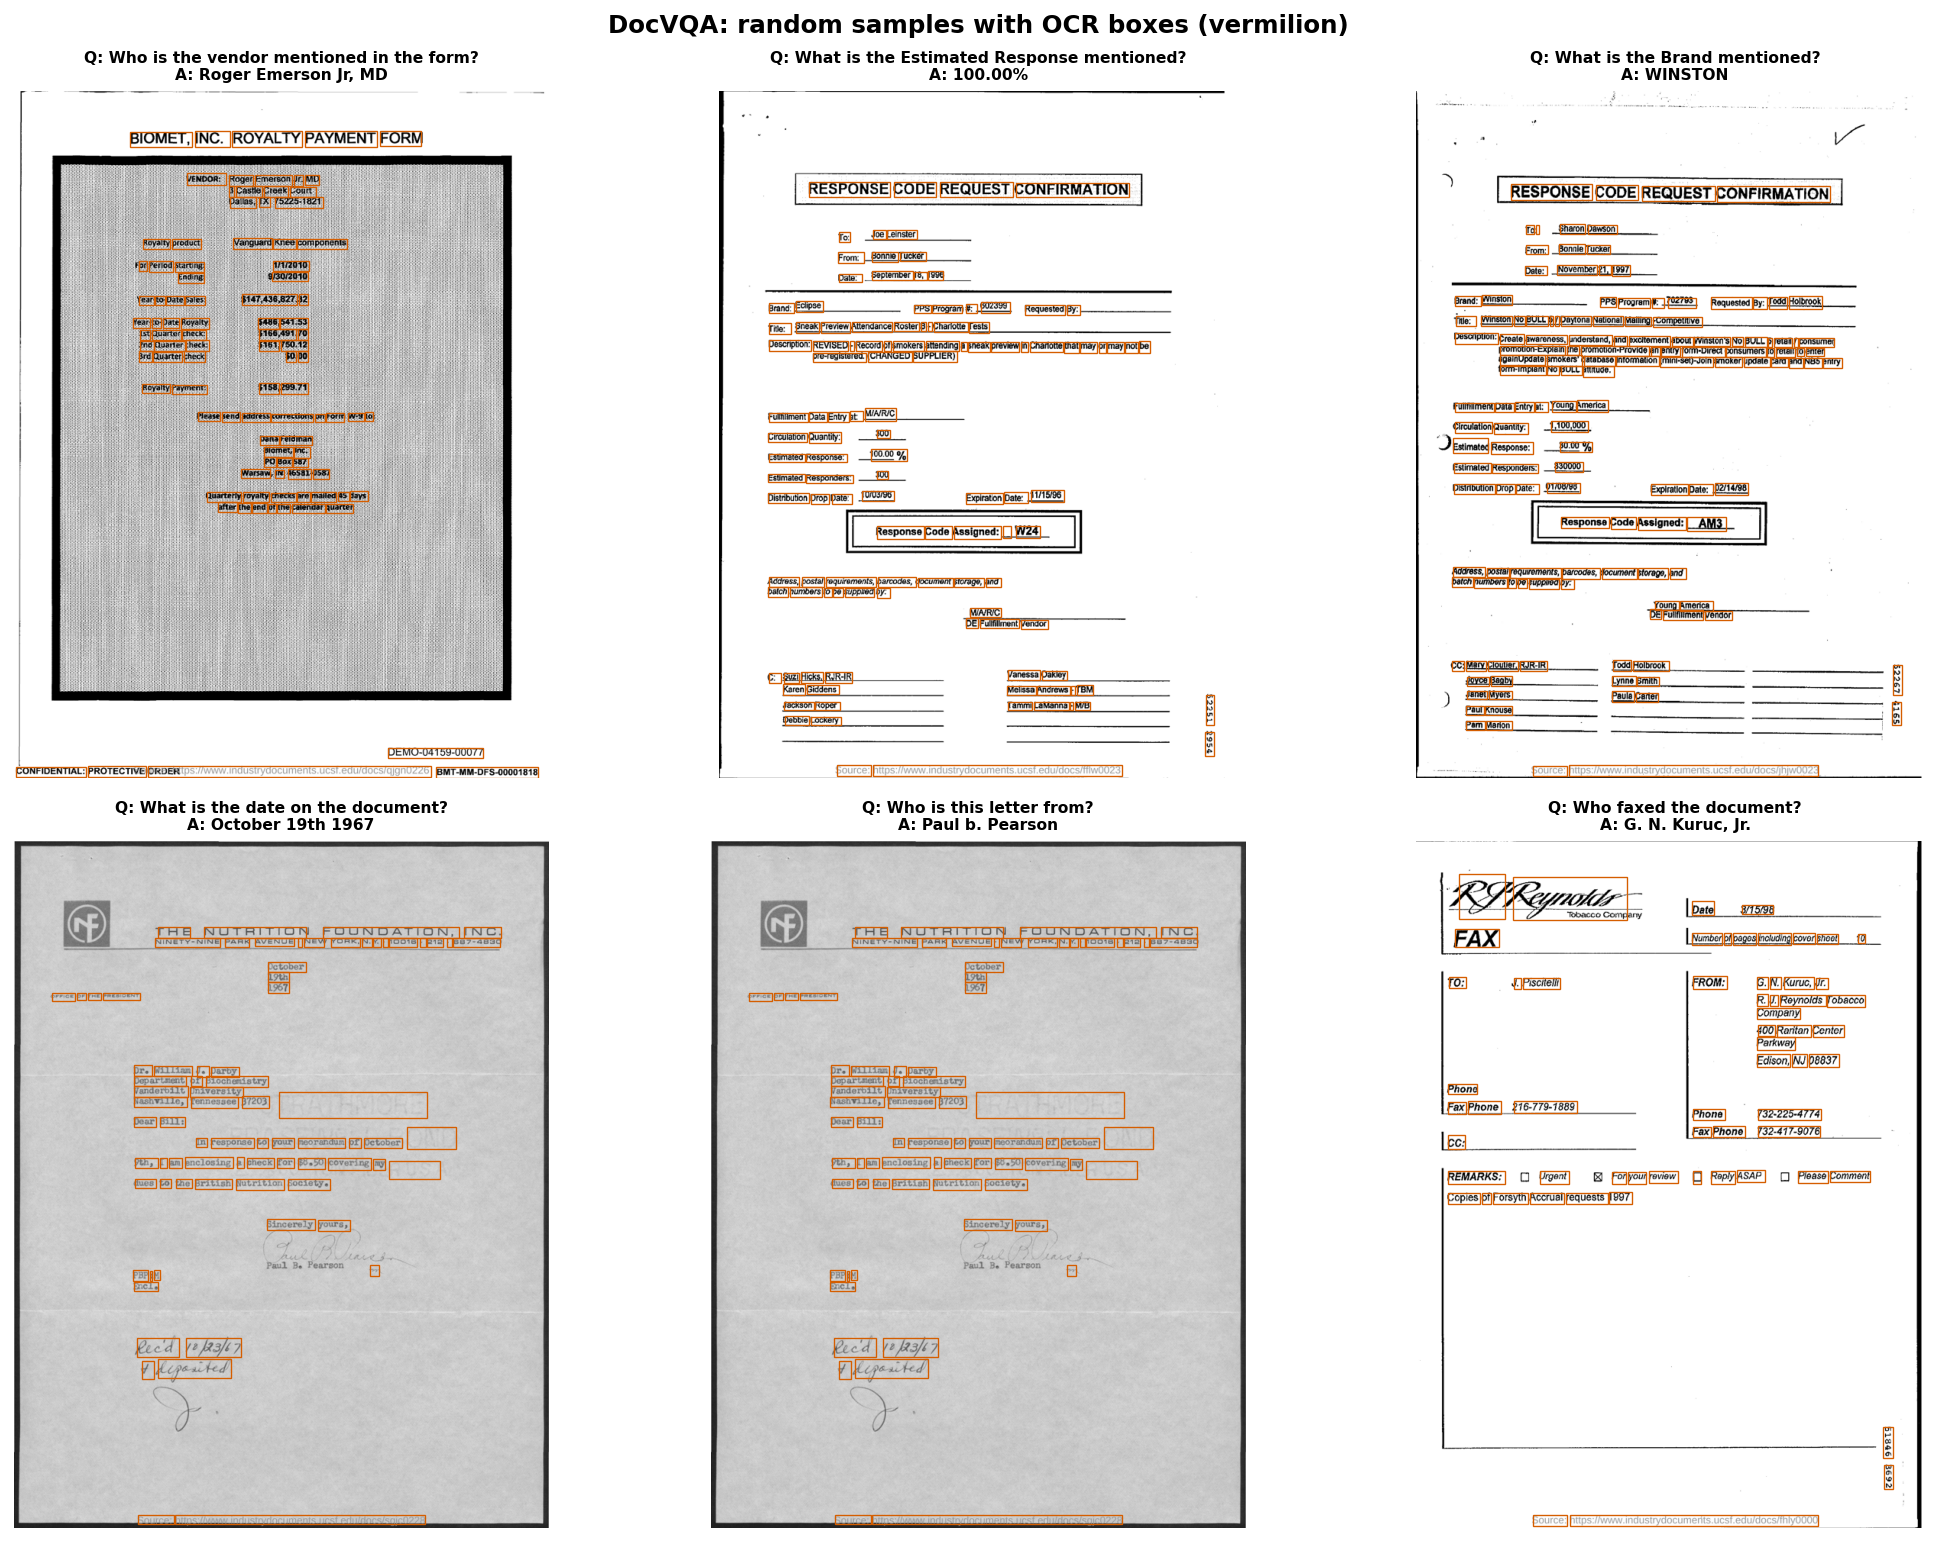

In [15]:
# 2.7 Visual gallery: random samples with OCR boxes, decoded as thumbnails only
gal = ACC.get("gallery", [])
if not gal:
    print("Gallery is empty (profile was loaded from cache). Set REUSE_CACHE=False to rebuild it.")
else:
    cols = 3
    rows_ = math.ceil(len(gal) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(5.2 * cols, 5.6 * rows_))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, g in zip(np.ravel(axes), gal):
        with PILImage.open(io.BytesIO(g["bytes"])) as im:
            im.draft("RGB", (900, 900))
            im = im.convert("RGB")
            im.thumbnail((900, 900))
        w, h = im.size
        ax.imshow(im)
        for b in g["boxes"]:
            if len(b) == 4:
                y0, x0, y1, x1 = b
                ax.add_patch(Rectangle((x0 / 1000 * w, y0 / 1000 * h), (x1 - x0) / 1000 * w, (y1 - y0) / 1000 * h,
                                       fill=False, edgecolor=OKABE_ITO["vermilion"], linewidth=0.7))
        ax.set_title(textwrap.fill(f"Q: {g['question']}", 55) + "\n" + textwrap.fill(f"A: {g['answer']}", 55), fontsize=8)
    fig.suptitle(f"{CFG['label']}: random samples with OCR boxes (vermilion)", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, f"{DATASET_KEY}_00_gallery")
    plt.show()
    del gal
    gc.collect()

# 3. Aggregation: Multidimensional Summarization

The central thesis metric is the **extractive ceiling**: how often the canonical answer can be copied straight from the
OCR tokens (`exact_token` / `contiguous_span`), compared with answers that need reformulation or visual reasoning
(`scattered_tokens` / `not_in_ocr`).

In [16]:
# 3.1 Answerability / extractive grounding audit
d = df.assign(split_=df["split_requested"].astype(str), ext_=df["extractive_class"].astype(str))
ext = d.groupby("split_")["ext_"].value_counts(normalize=True).mul(100).unstack(fill_value=0)
ext.loc["ALL"] = d["ext_"].value_counts(normalize=True).mul(100)
display(ext.round(2))
EXTRACTIVE_RATE = float(d["ext_"].isin(EXTRACTIVE_OK).mean())
ANY_ANSWER_RATE = float(df["any_answer_in_ocr"].mean())
print(f"Extractive ceiling (canonical answer = OCR token or contiguous span): {EXTRACTIVE_RATE:.2%}")
print(f"Relaxed ceiling (ANY ground-truth answer extractable):               {ANY_ANSWER_RATE:.2%}")

ext_,contiguous_span,exact_token,no_answer,not_in_ocr,scattered_tokens
split_,,,,,
train,49.1800,41.0200,0.0400,8.6000,1.1600
validation,47.6600,41.0600,0.0000,8.6400,2.6400
ALL,48.4200,41.0400,0.0200,8.6200,1.9000


Extractive ceiling (canonical answer = OCR token or contiguous span): 89.46%
Relaxed ceiling (ANY ground-truth answer extractable):               90.33%


In [17]:
# 3.2 Contingency cross-tabs: question starter × answer type, starter × extractive class
ct = pd.crosstab(df["question_starter"].astype(str), df["answer_type"].astype(str), normalize="index").mul(100)
ct["n"] = df["question_starter"].astype(str).value_counts()
display(ct.sort_values("n", ascending=False).style.format("{:.1f}").background_gradient(cmap="Blues", axis=None, subset=ct.columns[:-1]))
ct2 = pd.crosstab(df["question_starter"].astype(str), df["extractive_class"].astype(str), normalize="index").mul(100)
display(ct2.style.format("{:.1f}").background_gradient(cmap="Greens", axis=None))

answer_type,alphabetic,alphanumeric,numeric/date/amount,symbolic/other,yes/no,n
question_starter,,,,,,
what,37.7,15.9,46.1,0.3,0.0,6588.0
who/whose,99.8,0.2,0.0,0.0,0.0,982.0
which,78.0,10.0,11.9,0.0,0.0,628.0
embedded wh-word,62.1,14.6,23.4,0.0,0.0,556.0
when,2.6,65.7,31.7,0.0,0.0,268.0
how many,10.7,13.4,76.0,0.0,0.0,262.0
how much,1.2,10.8,87.5,0.4,0.0,240.0
other,83.7,2.6,11.9,0.0,1.8,227.0
where,89.6,10.4,0.0,0.0,0.0,135.0


extractive_class,contiguous_span,exact_token,no_answer,not_in_ocr,scattered_tokens
question_starter,,,,,
embedded wh-word,50.4,43.5,0.0,5.0,1.1
how (other),87.5,4.2,0.0,4.2,4.2
how many,19.8,71.0,0.0,8.0,1.1
how much,27.9,66.7,0.0,4.2,1.2
imperative (name/give),60.6,18.2,0.0,15.2,6.1
other,63.4,23.3,0.0,11.0,2.2
what,42.9,45.7,0.0,9.6,1.8
when,63.1,25.4,0.0,10.4,1.1
where,74.1,20.0,0.0,3.0,3.0


In [18]:
# 3.3 Continuous quartile bucketing: resolution × OCR density, question length × answer length
dq = df.assign(mp_quartile=pd.qcut(df["megapixels"], 4, duplicates="drop"),
               qlen_quartile=pd.qcut(df["question_len_tokens"].rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"]))
display(Markdown("**Megapixel quartile × OCR token count**"))
display(dq.groupby("mp_quartile", observed=True)["ocr_token_count"].agg(["count", "mean", "median", "std", "sum", "min", "max"]))
display(Markdown("**Question-length quartile × answer length (tokens)**"))
display(dq.groupby("qlen_quartile", observed=True)["answer_len_tokens"].agg(["count", "mean", "median", "std", "min", "max"]))

**Megapixel quartile × OCR token count**

,count,mean,median,std,sum,min,max
mp_quartile,,,,,,,
"(0.0865, 3.74]",2991,172.9773,130.0000,139.8798,517375,3,1018
"(3.74, 3.799]",3068,183.4788,163.0000,110.9228,562913,3,939
"(3.799, 3.933]",1446,232.3036,192.0000,147.0281,335911,12,1176
"(3.933, 38.657]",2495,195.0008,152.0000,152.9850,486527,5,1404


**Question-length quartile × answer length (tokens)**

,count,mean,median,std,min,max
qlen_quartile,,,,,,
Q1,2500,2.5712,2.0000,1.7377,0,18
Q2,2500,2.8036,2.0000,1.9286,1,24
Q3,2500,2.5316,2.0000,1.7329,0,26
Q4,2500,2.4188,2.0000,1.7518,1,17


In [19]:
# 3.4 Automated categorical × numeric group-bys
AGG_NUM = ["question_len_tokens", "answer_len_tokens", "ocr_token_count", "megapixels", "answer_agreement"]
for cat in ["split_requested", "question_starter", "answer_type", "extractive_class", "aspect_bucket"]:
    g = df.assign(**{cat: df[cat].astype(str)}).groupby(cat)[AGG_NUM].agg(["mean", "median"])
    g.insert(0, ("rows", "count"), df[cat].astype(str).value_counts())
    display(Markdown(f"**{cat}**"))
    display(g.sort_values(("rows", "count"), ascending=False).round(3))

**split_requested**

rows question_len_tokens        answer_len_tokens        ocr_token_count          megapixels        answer_agreement       
                count                mean median              mean median            mean   median       mean median             mean median
split_requested                                                                                                                             
train            5000              7.8740 8.0000            2.6330 2.0000        175.9400 151.0000     3.8750 3.7990           0.9550 1.0000
validation       5000              8.5030 8.0000            2.5300 2.0000        204.6060 167.0000     3.9470 3.7990           0.9400 1.0000

**question_starter**

rows question_len_tokens        answer_len_tokens        ocr_token_count          megapixels        answer_agreement       
                       count                mean median              mean median            mean   median       mean median             mean median
question_starter                                                                                                                                   
what                    6588              8.1840 8.0000            2.5800 2.0000        190.7070 159.0000     4.0090 3.7990           0.9600 1.0000
who/whose                982              7.2030 7.0000            2.8230 3.0000        186.8650 155.0000     3.6630 3.7990           0.9360 1.0000
which                    628              8.1910 8.0000            2.6700 2.0000        189.0780 141.0000     3.5380 3.7820           0.9260 1.0000
embedded wh-word         556             10.1600 9.0000            2.3420 2.0000        181.8540 151.5000     3.7200 3.7990           0.9020 1.0000
when                     268              6.9810 6.0000            3.0630 3.0000        182.7240 158.0000     4.0250 3.7990           0.9650 1.0000
how many                 262              9.0990 9.0000            1.4810 1.0000        213.8780 185.0000     3.8820 3.7990           0.8990 1.0000
how much                 240              9.9830 9.0000            2.2080 2.0000        185.2670 178.0000     3.9370 3.7990           0.9340 1.0000
other                    227              6.8060 7.0000            2.6520 2.0000        170.2860 124.0000     3.2530 3.7990           0.9060 1.0000
where                    135              7.2440 7.0000            3.0520 3.0000        212.7630 175.0000     3.6320 3.7990           0.8830 1.0000
yes/no (aux verb)         50              7.8800 8.0000            1.5800 1.0000        255.1200 233.0000     6.4150 3.7990           0.9630 1.0000
imperative (name/give)    33              8.3940 8.0000            2.7580 2.0000        211.4240 159.0000     3.3600 3.7990           0.9750 1.0000
how (other)               24              8.7500 9.0000            4.3750 3.0000        218.3330 178.0000     3.5830 3.7990           0.8820 1.0000
why                        7              6.4290 7.0000            5.1430 5.0000        167.8570 117.0000     3.4360 3.7870           0.9290 1.0000

**answer_type**

rows question_len_tokens        answer_len_tokens        ocr_token_count          megapixels        answer_agreement       
                    count                mean median              mean median            mean   median       mean median             mean median
answer_type                                                                                                                                     
alphabetic           4707              7.8520 7.0000            2.9630 3.0000        197.2490 159.0000     3.6830 3.7990           0.9360 1.0000
numeric/date/amount  3774              8.6400 8.0000            1.8260 2.0000        183.1940 156.0000     4.2250 3.7990           0.9670 1.0000
alphanumeric         1460              8.1050 8.0000            3.3520 3.0000        184.4550 156.0000     3.6730 3.7990           0.9350 1.0000
yes/no                 39              7.3850 8.0000            1.0000 1.0000        264.0510 241.0000     7.2250 3.7990           0.9830 1.0000
symbolic/other         20              9.5500 9.5000            2.0500 2.0000        164.9000 142.5000     8.9420 3.7990           0.9540 1.0000

**extractive_class**

rows question_len_tokens        answer_len_tokens        ocr_token_count          megapixels        answer_agreement       
                 count                mean median              mean median            mean   median       mean median             mean median
extractive_class                                                                                                                             
contiguous_span   4842              7.9420 8.0000            3.3440 3.0000        189.7360 153.5000     3.6620 3.7990           0.9360 1.0000
exact_token       4104              8.5300 8.0000            1.5620 1.0000        188.7220 162.0000     4.2440 3.7990           0.9650 1.0000
not_in_ocr         862              7.9080 7.0000            2.6980 2.0000        185.8760 146.5000     3.7700 3.7990           0.9410 1.0000
scattered_tokens   190              8.3790 8.0000            4.6420 3.0000        258.1740 184.5000     3.7070 3.8100           0.8910 1.0000
no_answer            2              6.5000 6.5000            0.0000 0.0000        116.5000 116.5000     3.9340 3.9340              NaN    NaN

**aspect_bucket**

rows question_len_tokens        answer_len_tokens        ocr_token_count          megapixels        answer_agreement       
                  count                mean median              mean median            mean   median       mean median             mean median
aspect_bucket                                                                                                                                 
portrait (<0.8)    8374              8.1200 8.0000            2.5770 2.0000        195.6480 164.0000     3.9430 3.7990           0.9490 1.0000
landscape (>1.25)  1365              8.6250 8.0000            2.5890 2.0000        155.6620 113.0000     3.9210 3.7400           0.9410 1.0000
square (0.8-1.25)   261              8.0840 7.0000            2.6900 2.0000        198.8240 139.0000     2.8080 2.6320           0.9530 1.0000

In [20]:
# 3.5 Train ↔ validation drift (chi-square for categoricals, KS for numerics)
tr_m, va_m = df["split_requested"].astype(str) == "train", df["split_requested"].astype(str) == "validation"
rows = []
if tr_m.any() and va_m.any():
    for c in ["question_starter", "answer_type", "extractive_class", "aspect_bucket"]:
        tab = pd.crosstab(df[c].astype(str), df["split_requested"].astype(str))
        chi2, p, dof, _ = stats.chi2_contingency(tab)
        v = math.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))) if min(tab.shape) > 1 else np.nan
        rows.append({"feature": c, "test": "chi-square", "statistic": chi2, "p_value": p, "effect": f"Cramér's V={v:.3f}"})
    for c in ["megapixels", "question_len_tokens", "answer_len_tokens", "ocr_token_count"]:
        a, b = df.loc[tr_m, c].dropna(), df.loc[va_m, c].dropna()
        ks = stats.ks_2samp(a, b)
        rows.append({"feature": c, "test": "KS", "statistic": ks.statistic, "p_value": ks.pvalue, "effect": f"D={ks.statistic:.3f}"})
    display(pd.DataFrame(rows).set_index("feature"))
    print("Read the effect sizes (Cramér's V, D), not only p-values: with thousands of rows tiny shifts are 'significant'.")

,test,statistic,p_value,effect
feature,,,,
question_starter,chi-square,214.8316,0.0000,Cramér's V=0.147
answer_type,chi-square,95.7316,0.0000,Cramér's V=0.098
extractive_class,chi-square,32.0196,0.0000,Cramér's V=0.057
aspect_bucket,chi-square,190.6187,0.0000,Cramér's V=0.138
megapixels,KS,0.1878,0.0000,D=0.188
question_len_tokens,KS,0.1026,0.0000,D=0.103
answer_len_tokens,KS,0.0884,0.0000,D=0.088
ocr_token_count,KS,0.1082,0.0000,D=0.108


Read the effect sizes (Cramér's V, D), not only p-values: with thousands of rows tiny shifts are 'significant'.


In [21]:
# 3.6 Pareto 80/20 answer concentration & metadata categories
CONC = answer_concentration(df)
print(f"Unique normalised answers: {CONC['unique_answers']:,} | top-1 '{CONC.get('top1_answer')}' = {CONC['top1_share']:.2%}")
print(f"Answers needed to cover 50% of questions: {CONC['n_for_50pct']:,} | 80%: {CONC['n_for_80pct']:,} "
      f"({CONC['n_for_80pct']/max(CONC['unique_answers'],1):.1%} of the answer vocabulary)")
display(CONC["counts"].head(20).rename("count").to_frame().assign(share_pct=lambda t: 100 * t["count"] / CONC["counts"].sum()))
for c in [c for c in df.columns if c.startswith("meta__") and df[c].notna().any()]:
    exploded = df[c].dropna().astype(str).str.split("|").explode()
    if 1 < exploded.nunique() <= 5000:
        display(Markdown(f"**Metadata `{c[6:]}`: top categories** ({exploded.nunique():,} distinct)"))
        display(exploded.value_counts().head(15).rename("count").to_frame())
if not any(pd.api.types.is_datetime64_any_dtype(df[c]) for c in df.columns):
    print("Temporal resampling: skipped (the canonical schema has no datetime fields).")

Unique normalised answers: 7,438 | top-1 '2' = 0.67%
Answers needed to cover 50% of questions: 2,440 | 80%: 5,439 (73.1% of the answer vocabulary)


,count,share_pct
answer_norm,,
2,67,0.6701
3,51,0.5101
1,40,0.4001
4,38,0.3801
5,28,0.2801
winston,27,0.2701
12,27,0.2701
6,25,0.2501
10,25,0.2501


**Metadata `question_types`: top categories** (9 distinct)

,count
meta__question_types,
layout,3787
form,2880
table/list,2849
free_text,1322
handwritten,587
others,339
figure/diagram,284
Image/Photo,104
Yes/No,33


**Metadata `docId`: top categories** (2,616 distinct)

...

**Metadata `ucsf_document_id`: top categories** (1,693 distinct)

,count
meta__ucsf_document_id,
qjgn0226,315
snbx0223,86
rmwn0226,67
rxvh0227,55
yscw0217,45
fkxn0226,42
krcy0227,41
jzhd0227,40
hjxn0226,40


**Metadata `ucsf_document_page_no`: top categories** (178 distinct)

,count
meta__ucsf_document_page_no,
1,3106
2,1193
3,744
4,466
5,415
7,331
6,305
9,259
8,226


Temporal resampling: skipped (the canonical schema has no datetime fields).


# 4. Visualization: High-Contrast & Accessible Storytelling

All figures use the Okabe-Ito palette, black edges, hatch patterns (so they still read in greyscale print), annotated
values and 140 DPI. Every PNG is saved to `reports/figures/`. Distribution panels clip the display at p99.5; the
statistics above use the unclipped data.

[saved] reports/figures/docvqa_01_missingness.png


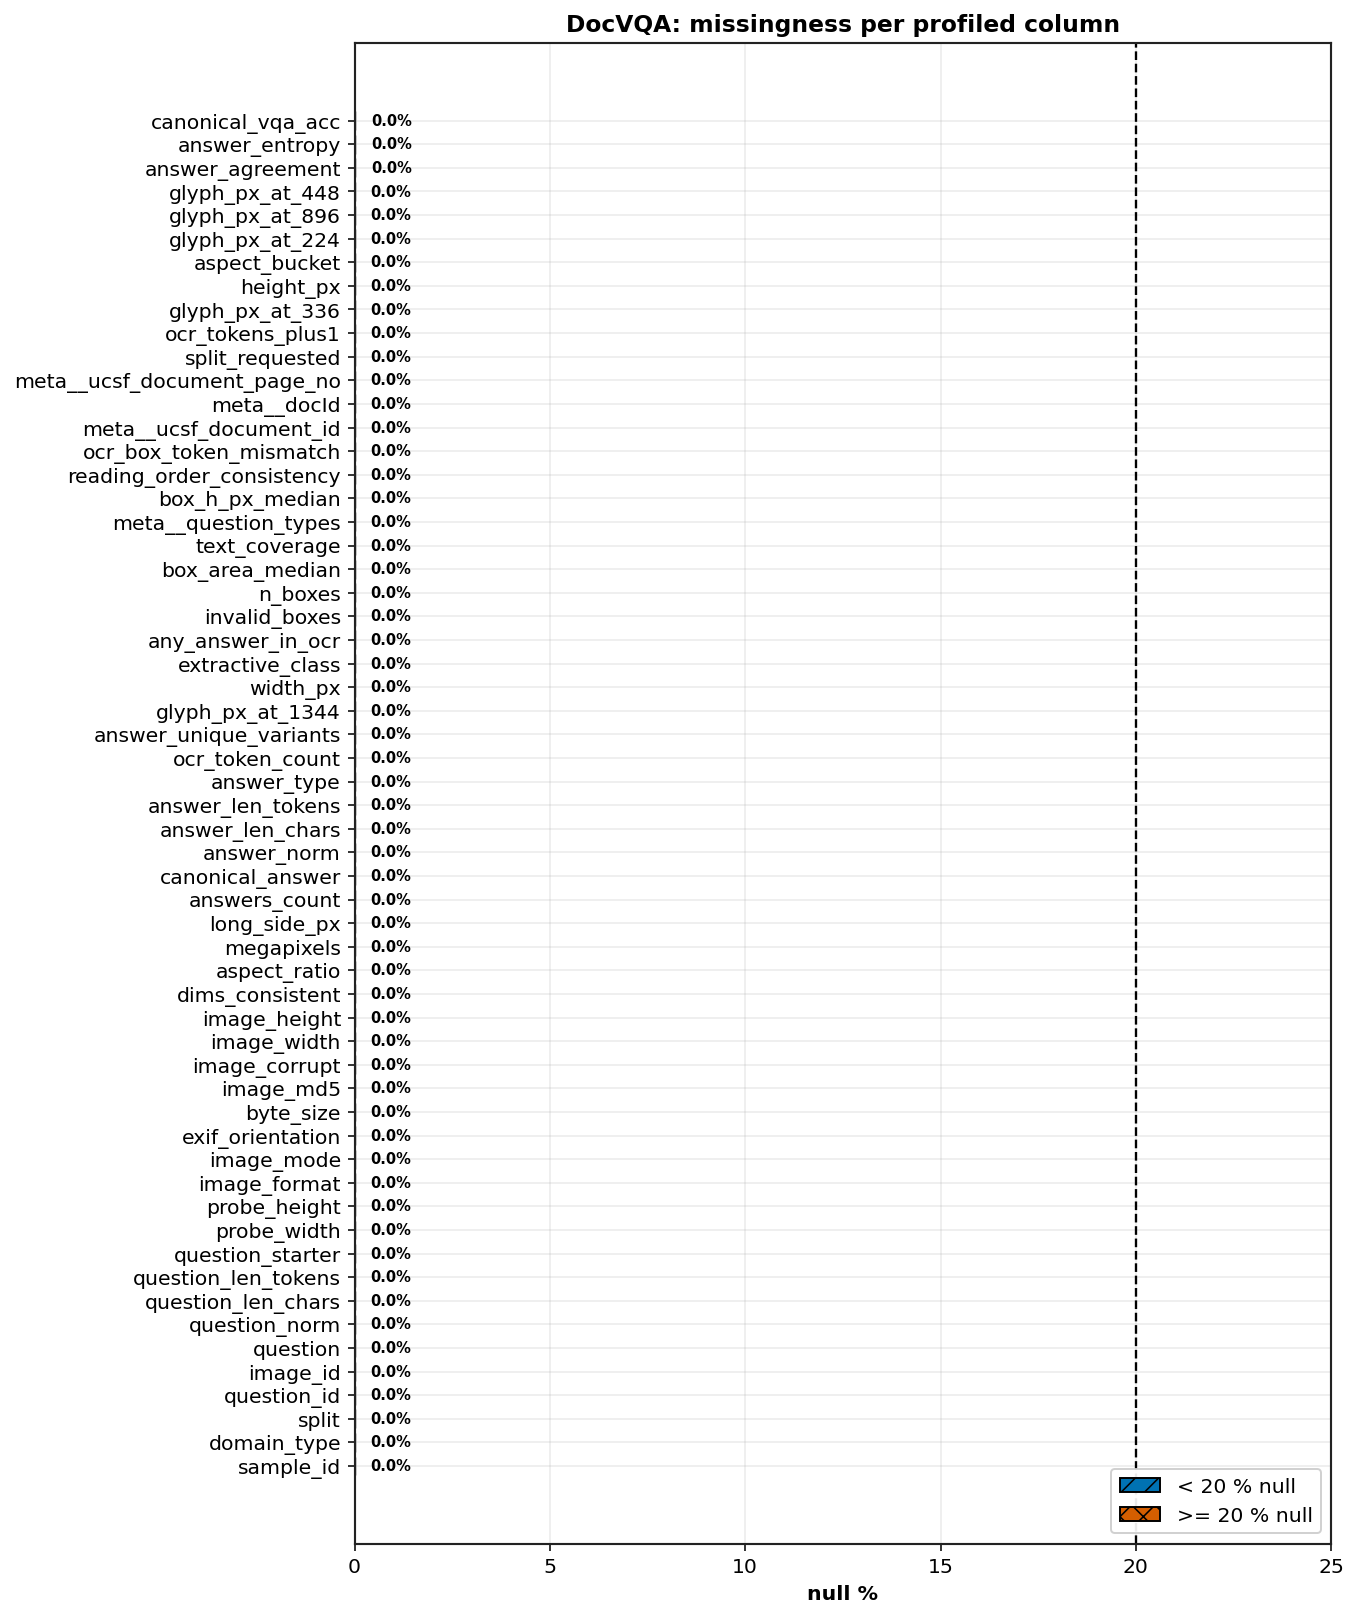

In [22]:
# 4.1 Missingness bar chart (hatched; vermilion + 'xx' = >= 20 % null)
null_pct = (df.isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, max(3.5, 0.24 * len(null_pct))))
bars = ax.barh(null_pct.index, null_pct.values, edgecolor="black", linewidth=0.7,
               color=[OKABE_ITO["vermilion"] if v >= 20 else CFG["color"] for v in null_pct.values])
for b, v in zip(bars, null_pct.values):
    b.set_hatch("xx" if v >= 20 else CFG["hatch"])
    ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontsize=7.5, fontweight="bold")
ax.axvline(20, ls="--", color="black", lw=1.2)
ax.set_xlim(0, max(25, null_pct.max() * 1.15))
ax.set_xlabel("null %")
ax.set_title(f"{CFG['label']}: missingness per profiled column")
ax.legend(handles=[Patch(facecolor=CFG["color"], hatch=CFG["hatch"], edgecolor="black", label="< 20 % null"),
                   Patch(facecolor=OKABE_ITO["vermilion"], hatch="xx", edgecolor="black", label=">= 20 % null")], loc="lower right")
save_fig(fig, f"{DATASET_KEY}_01_missingness")
plt.show()

[saved] reports/figures/docvqa_02_correlation.png


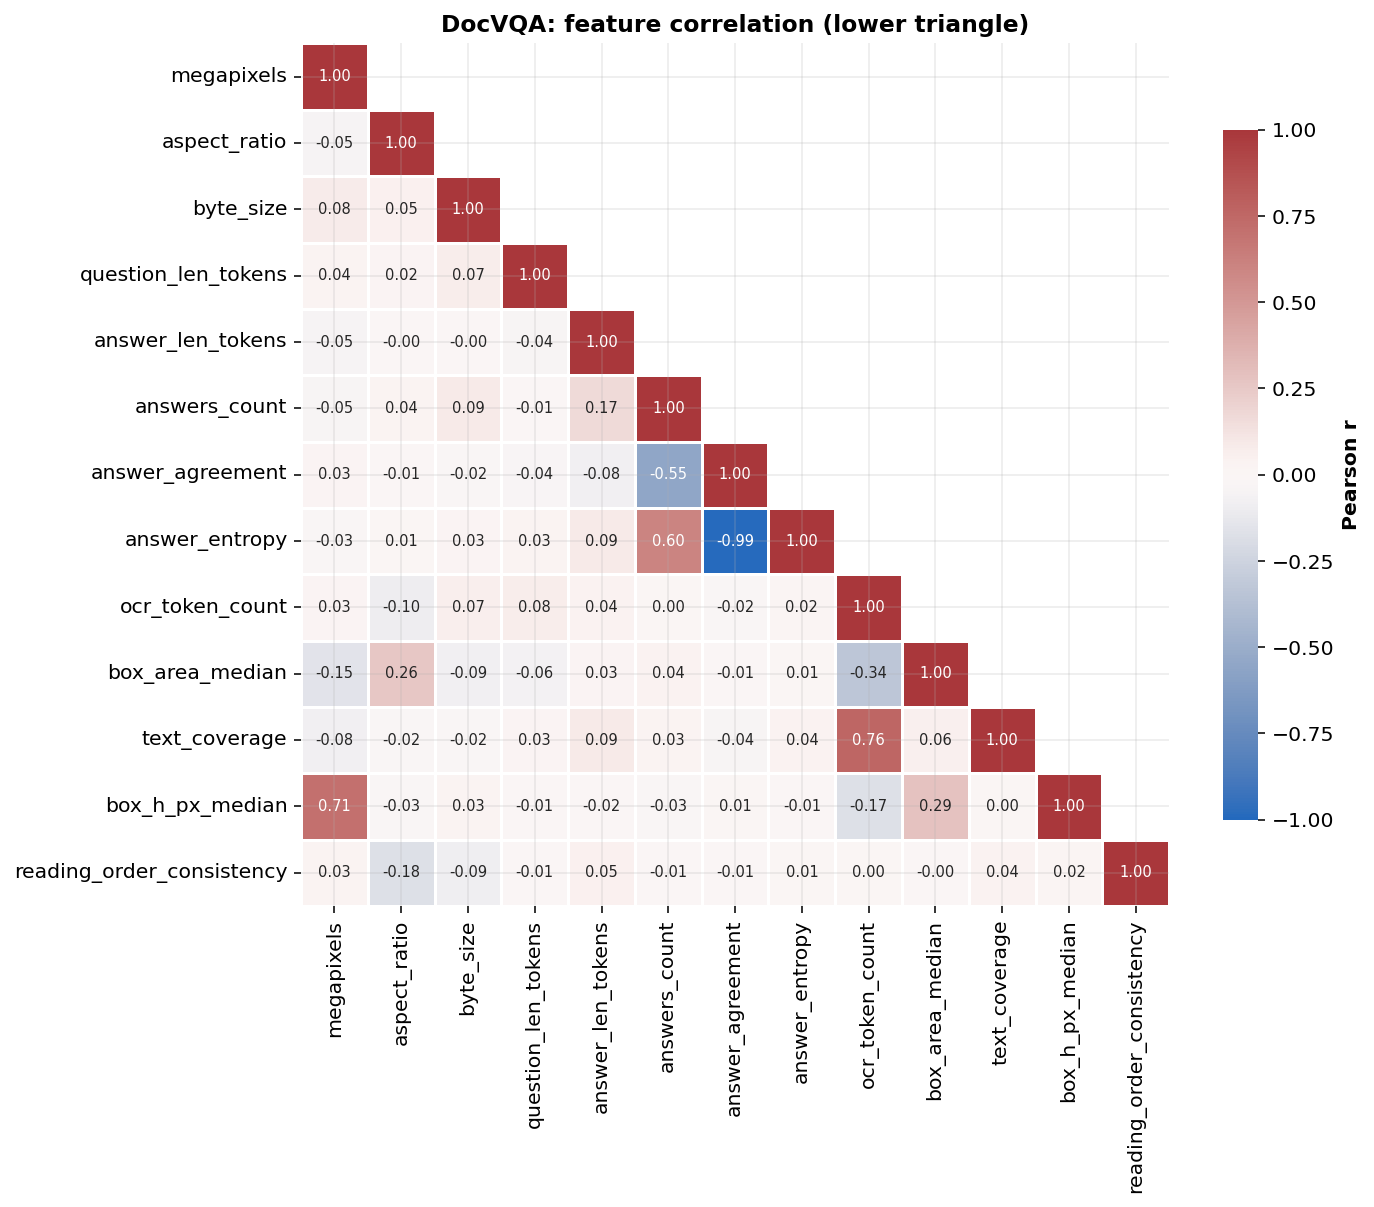

In [23]:
# 4.2 Correlation heatmap (diverging, masked upper triangle, annotated)
KEY_NUMERIC = ["megapixels", "aspect_ratio", "byte_size", "question_len_tokens", "answer_len_tokens", "answers_count",
               "answer_agreement", "answer_entropy", "ocr_token_count", "box_area_median", "text_coverage",
               "box_h_px_median", "reading_order_consistency"]
cols = [c for c in KEY_NUMERIC if c in df and df[c].nunique() > 1]
corr = df[cols].astype(float).corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
ax.set_title(f"{CFG['label']}: feature correlation (lower triangle)")
save_fig(fig, f"{DATASET_KEY}_02_correlation")
plt.show()

[saved] reports/figures/docvqa_03_distributions.png


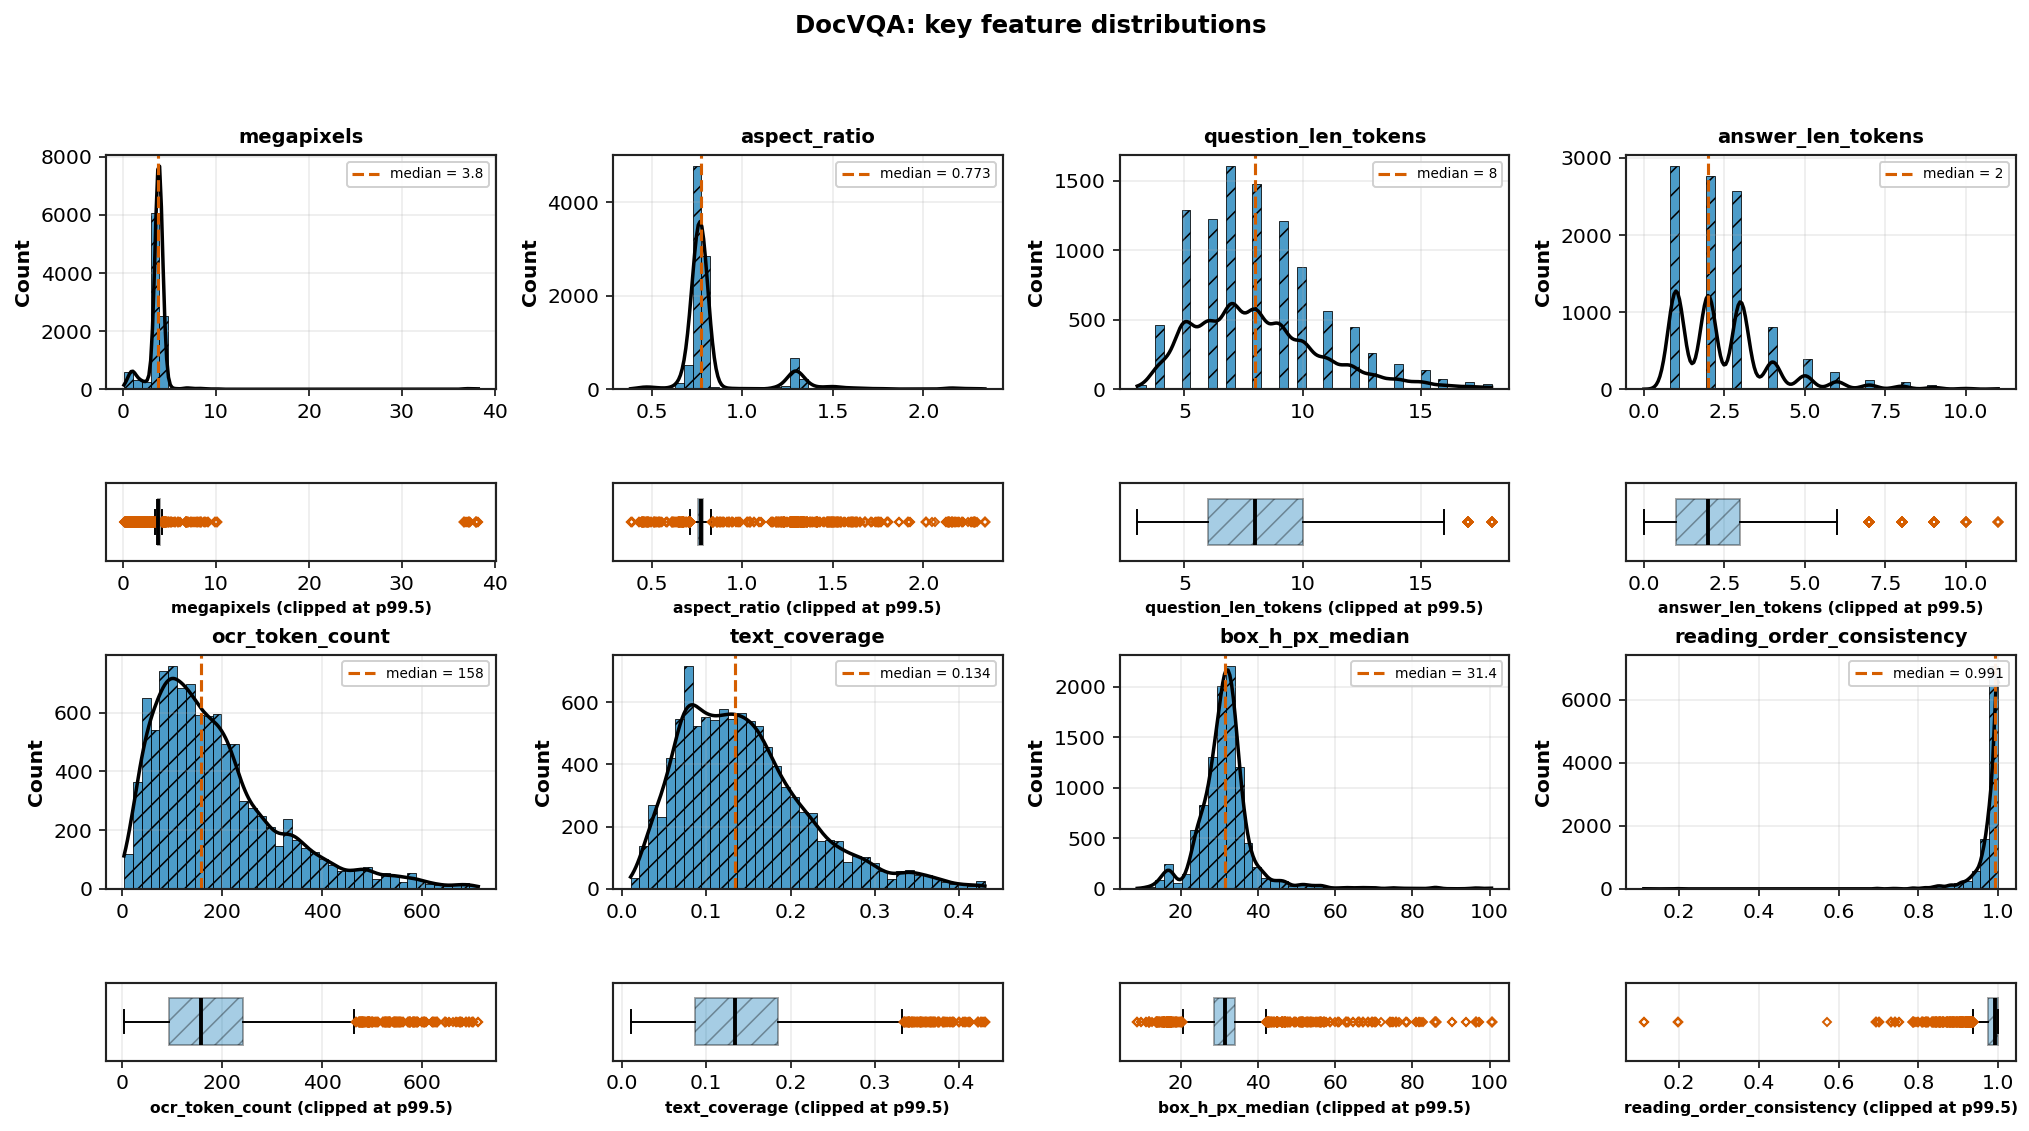

In [24]:
# 4.3 Distribution grid: histogram + KDE above, boxplot with diamond outliers below
DIST_FEATURES = ["megapixels", "aspect_ratio", "question_len_tokens", "answer_len_tokens",
                 "ocr_token_count", "text_coverage", "box_h_px_median", "reading_order_consistency"]
feats = [f for f in DIST_FEATURES if f in df and df[f].notna().sum() > 1]
ncols = 4
nblocks = math.ceil(len(feats) / ncols)
fig = plt.figure(figsize=(4.4 * ncols, 4.2 * nblocks))
gs = fig.add_gridspec(2 * nblocks, ncols, height_ratios=[3, 1] * nblocks, hspace=0.6, wspace=0.3)
for i, f in enumerate(feats):
    r, c = divmod(i, ncols)
    x = df[f].dropna().astype(float)
    xs = x[x <= x.quantile(0.995)]
    ax_h = fig.add_subplot(gs[2 * r, c])
    ax_b = fig.add_subplot(gs[2 * r + 1, c], sharex=ax_h)
    sns.histplot(xs, bins=40, kde=True, color=CFG["color"], edgecolor="black", linewidth=0.4, alpha=0.7, ax=ax_h)
    for p in ax_h.patches:
        p.set_hatch(CFG["hatch"])
    for ln in ax_h.lines:
        ln.set_color("black"); ln.set_linewidth(1.8)
    ax_h.axvline(x.median(), color=OKABE_ITO["vermilion"], ls="--", lw=1.6, label=f"median = {x.median():.3g}")
    ax_h.legend(fontsize=7, loc="upper right")
    ax_h.set_title(f, fontsize=10)
    ax_h.set_xlabel("")
    ax_b.boxplot(xs, vert=False, widths=0.6, patch_artist=True,
                 boxprops=dict(facecolor=CFG["color"], alpha=0.35, edgecolor="black", hatch=CFG["hatch"]),
                 medianprops=dict(color="black", lw=2),
                 flierprops=dict(marker="D", markerfacecolor="none", markeredgecolor=OKABE_ITO["vermilion"], markersize=3))
    ax_b.set_yticks([])
    ax_b.set_xlabel(f"{f} (clipped at p99.5)", fontsize=8)
fig.suptitle(f"{CFG['label']}: key feature distributions", fontweight="bold", y=1.0)
save_fig(fig, f"{DATASET_KEY}_03_distributions")
plt.show()

[saved] reports/figures/docvqa_04_categorical.png


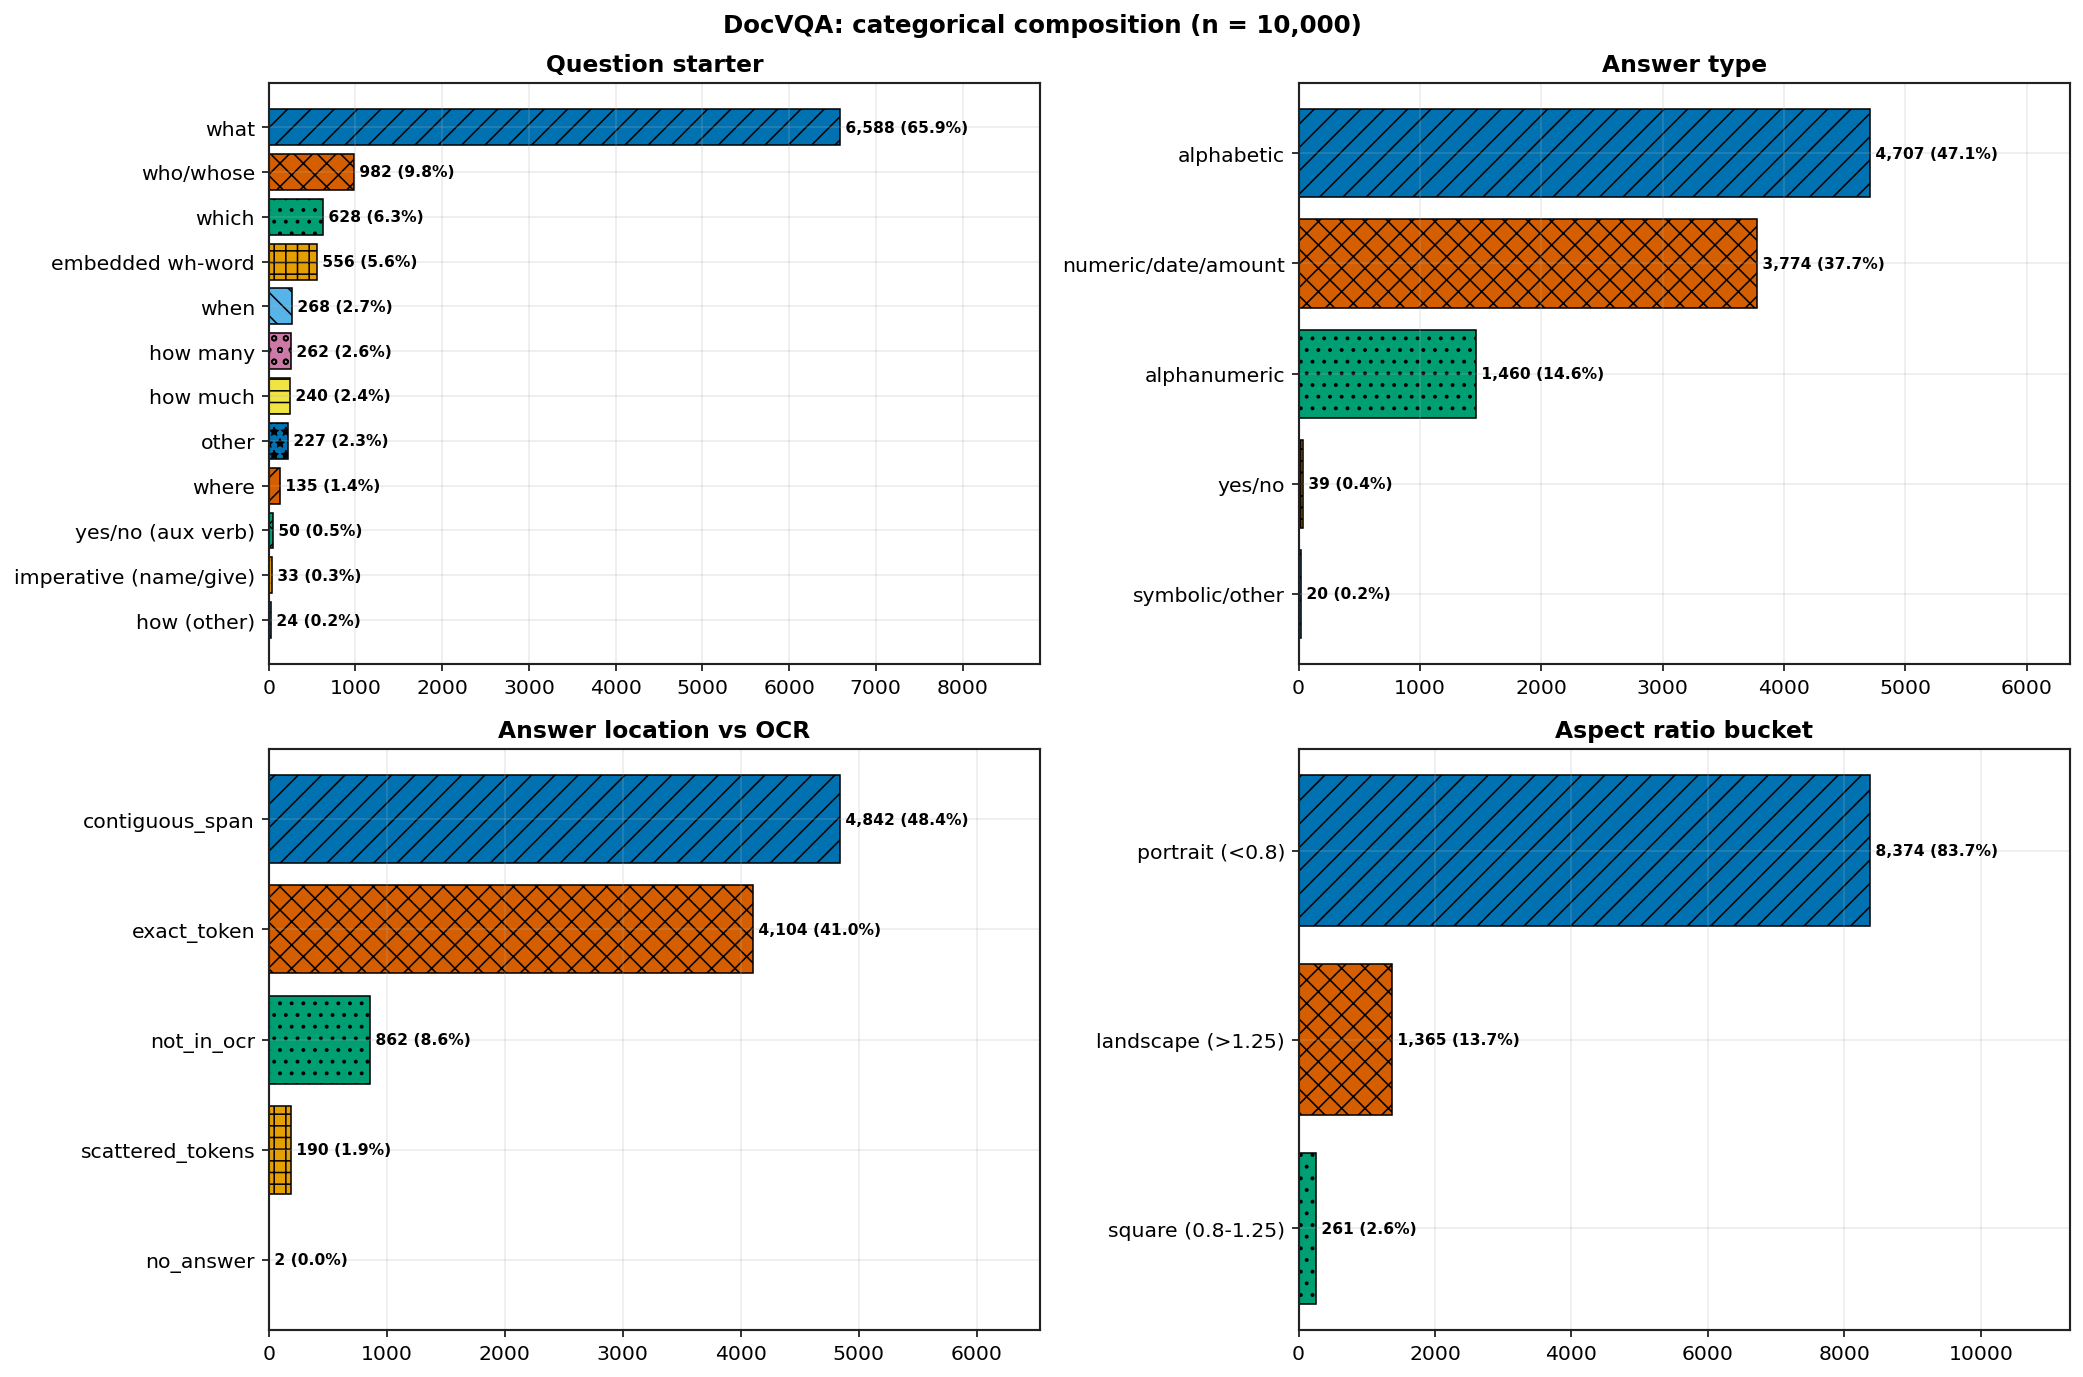

In [25]:
# 4.4 Categorical composition (distinct hatch per bar, count + % annotations)
def hbar_counts(ax, series, title, top=12):
    vc = series.astype(str).value_counts().head(top)[::-1]
    total = len(series)
    n = len(vc)
    bars = ax.barh(vc.index, vc.values, edgecolor="black", linewidth=0.8,
                   color=[PALETTE[(n - 1 - i) % len(PALETTE)] for i in range(n)])
    for i, (b, v) in enumerate(zip(bars, vc.values)):
        b.set_hatch(HATCHES[(n - 1 - i) % len(HATCHES)])
        ax.text(v, b.get_y() + b.get_height() / 2, f" {v:,} ({v/total:.1%})", va="center", fontsize=8, fontweight="bold")
    ax.set_xlim(0, vc.max() * 1.35)
    ax.set_title(title)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, title) in zip(axes.flat, [("question_starter", "Question starter"), ("answer_type", "Answer type"),
                                        ("extractive_class", "Answer location vs OCR"), ("aspect_bucket", "Aspect ratio bucket")]):
    hbar_counts(ax, df[col], title)
fig.suptitle(f"{CFG['label']}: categorical composition (n = {len(df):,})", fontweight="bold")
fig.tight_layout()
save_fig(fig, f"{DATASET_KEY}_04_categorical")
plt.show()

[saved] reports/figures/docvqa_05_spatial.png


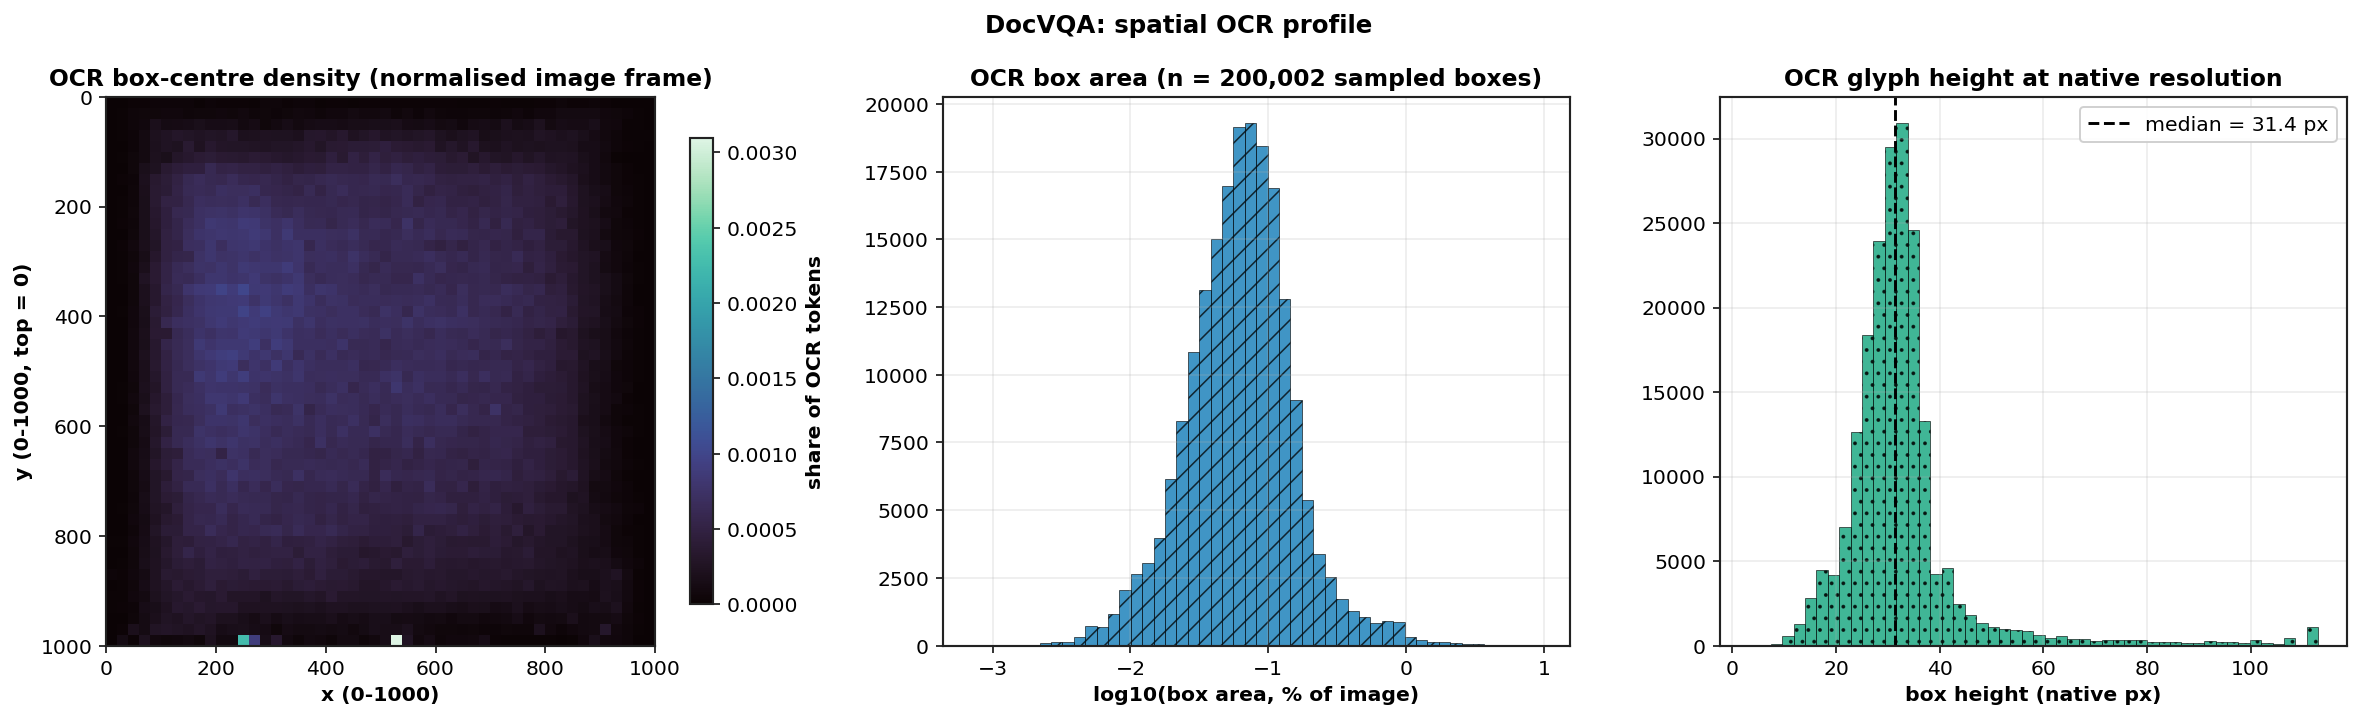

In [26]:
# 4.5 OCR spatial dispersion: box-centre density + box-level size distributions
H = ACC["hist"]
dens = H / H.sum() if H.sum() else H
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})
im = axes[0].imshow(dens, cmap=SEQ_CMAP, extent=[0, 1000, 1000, 0], interpolation="nearest")
fig.colorbar(im, ax=axes[0], shrink=0.85, label="share of OCR tokens")
axes[0].set_title("OCR box-centre density (normalised image frame)")
axes[0].set_xlabel("x (0-1000)"); axes[0].set_ylabel("y (0-1000, top = 0)"); axes[0].grid(False)
area = np.asarray(ACC["box_area"]); area = area[area > 0]
if area.size:
    axes[1].hist(np.log10(area * 100), bins=50, color=CFG["color"], edgecolor="black", linewidth=0.4, hatch=CFG["hatch"], alpha=0.75)
    axes[1].set_xlabel("log10(box area, % of image)")
axes[1].set_title(f"OCR box area (n = {area.size:,} sampled boxes)")
hpx = np.asarray(ACC["box_h_px"]); hpx = hpx[hpx > 0]
if hpx.size:
    axes[2].hist(np.clip(hpx, 0, np.quantile(hpx, 0.995)), bins=50, color=OKABE_ITO["green"], edgecolor="black",
                 linewidth=0.4, hatch="..", alpha=0.75)
    axes[2].axvline(np.median(hpx), color="black", ls="--", lw=1.5, label=f"median = {np.median(hpx):.1f} px")
    axes[2].legend()
    axes[2].set_xlabel("box height (native px)")
axes[2].set_title("OCR glyph height at native resolution")
fig.suptitle(f"{CFG['label']}: spatial OCR profile", fontweight="bold")
fig.tight_layout()
save_fig(fig, f"{DATASET_KEY}_05_spatial")
plt.show()

[saved] reports/figures/docvqa_06_legibility.png


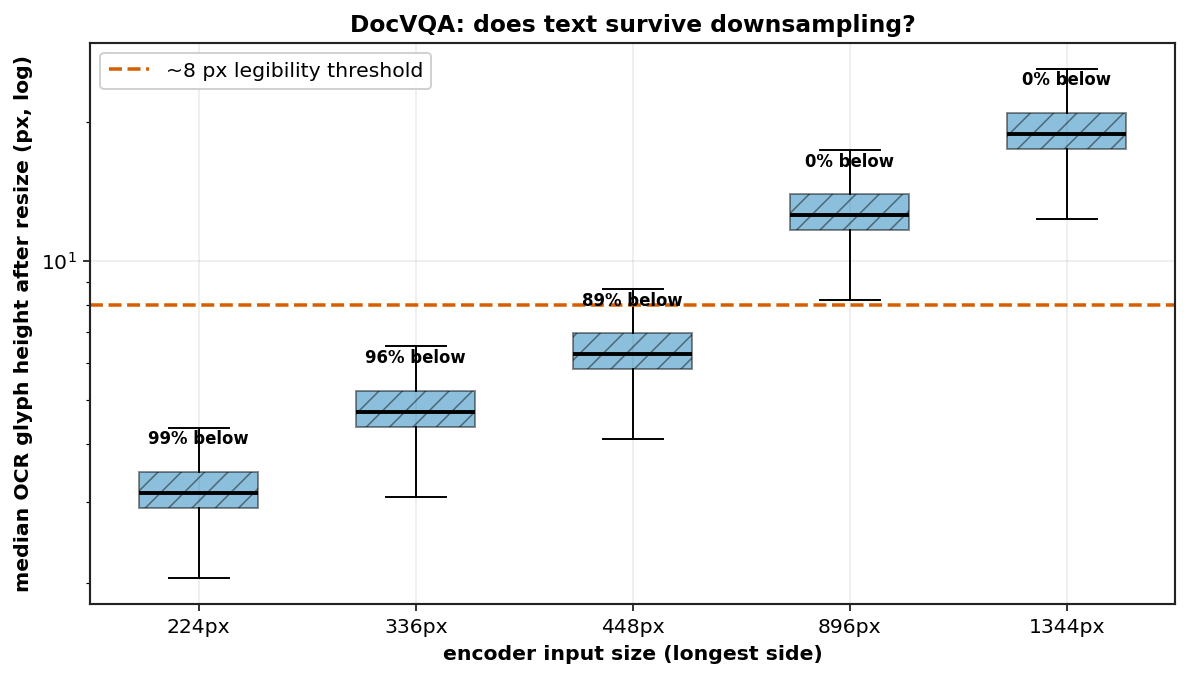

In [27]:
# 4.6 Legibility vs encoder input size (median glyph height after aspect-preserving resize)
data = [df[f"glyph_px_at_{R}"].dropna().astype(float).values for R in ENCODER_RESOLUTIONS]
fig, ax = plt.subplots(figsize=(10, 5.2))
bp = ax.boxplot(data, positions=range(len(ENCODER_RESOLUTIONS)), widths=0.55, patch_artist=True, showfliers=False,
                medianprops=dict(color="black", lw=2))
for patch in bp["boxes"]:
    patch.set(facecolor=CFG["color"], alpha=0.45, edgecolor="black", hatch=CFG["hatch"])
ax.axhline(LEGIBILITY_PX, color=OKABE_ITO["vermilion"], ls="--", lw=1.8, label=f"~{LEGIBILITY_PX} px legibility threshold")
for i, arr in enumerate(data):
    if arr.size:
        ax.text(i, ax.get_ylim()[1] if False else np.quantile(arr, 0.75) * 1.15, f"{(arr < LEGIBILITY_PX).mean():.0%} below",
                ha="center", fontsize=8.5, fontweight="bold")
ax.set_xticks(range(len(ENCODER_RESOLUTIONS)))
ax.set_xticklabels([f"{R}px" for R in ENCODER_RESOLUTIONS])
ax.set_yscale("log")
ax.set_xlabel("encoder input size (longest side)")
ax.set_ylabel("median OCR glyph height after resize (px, log)")
ax.set_title(f"{CFG['label']}: does text survive downsampling?")
ax.legend(loc="upper left")
save_fig(fig, f"{DATASET_KEY}_06_legibility")
plt.show()

[saved] reports/figures/docvqa_07_pareto.png


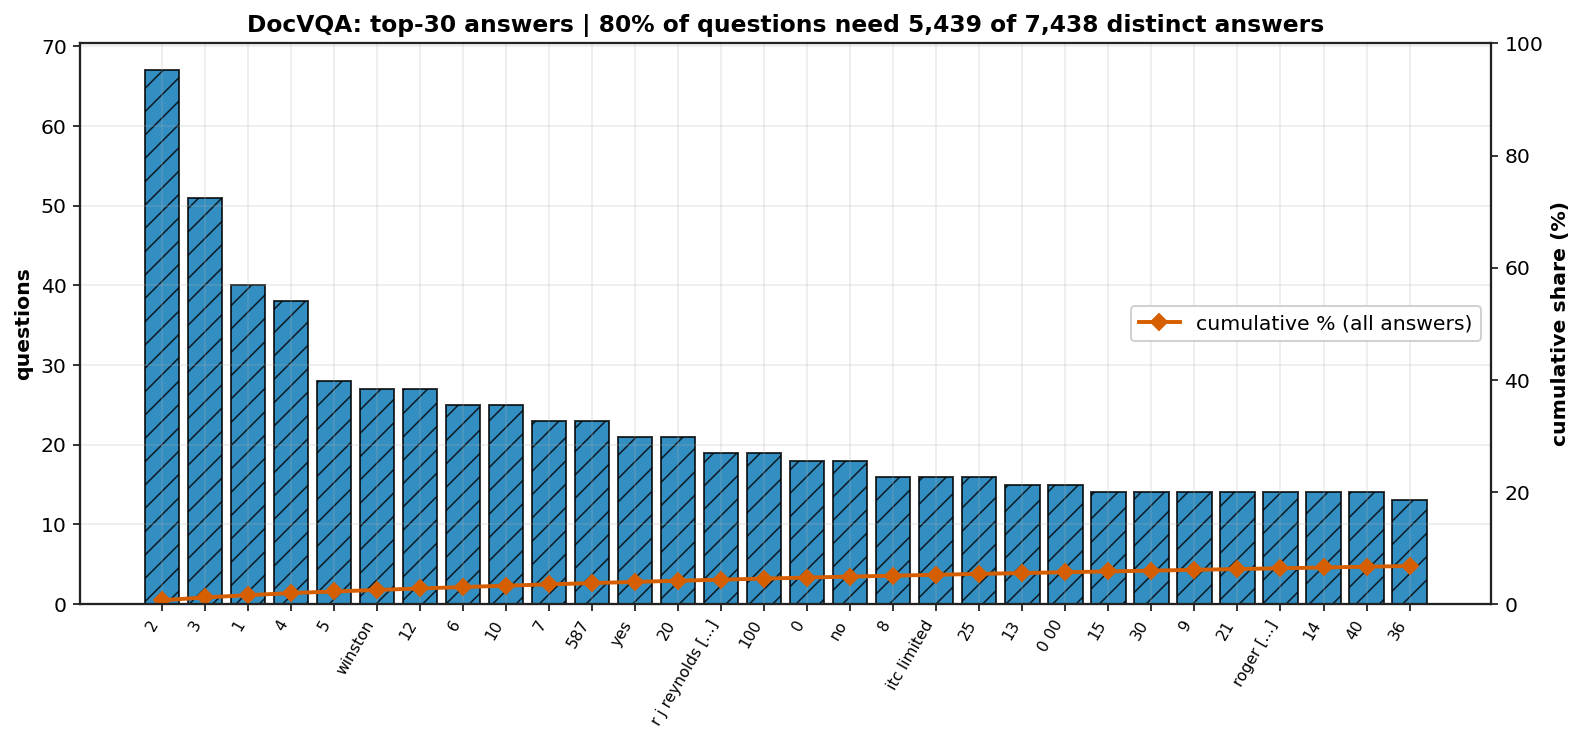

In [28]:
# 4.7 Pareto chart of answer concentration
counts = CONC["counts"]
top = counts.head(30)
cum = counts.cumsum() / counts.sum() * 100
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.bar(range(len(top)), top.values, color=CFG["color"], edgecolor="black", hatch=CFG["hatch"], alpha=0.8)
ax.set_xticks(range(len(top)))
ax.set_xticklabels([textwrap.shorten(s, 18) for s in top.index], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("questions")
ax2 = ax.twinx()
ax2.plot(range(len(top)), cum.head(30).values, color=OKABE_ITO["vermilion"], marker="D", lw=2, label="cumulative % (all answers)")
ax2.set_ylim(0, 100); ax2.set_ylabel("cumulative share (%)"); ax2.grid(False)
ax2.legend(loc="center right")
ax.set_title(f"{CFG['label']}: top-30 answers | 80% of questions need {CONC['n_for_80pct']:,} of {CONC['unique_answers']:,} distinct answers")
save_fig(fig, f"{DATASET_KEY}_07_pareto")
plt.show()

In [29]:
# 4.8 Interactive Plotly explorer: click legend entries to slice by class; hover for question/answer
plot_df = df.sample(min(len(df), 4000), random_state=SEED).copy()
for c in ["extractive_class", "split_requested", "answer_type", "question_starter"]:
    plot_df[c] = plot_df[c].astype(str)
fig = px.scatter(plot_df, x="megapixels", y="ocr_tokens_plus1", color="extractive_class", symbol="split_requested",
                 hover_data=["question", "canonical_answer", "answer_type", "question_starter"], log_y=True,
                 color_discrete_sequence=PALETTE, template="plotly_white",
                 labels={"ocr_tokens_plus1": "OCR tokens + 1 (log)", "megapixels": "image megapixels"},
                 title=f"{CFG['label']}: resolution vs OCR density by answer location")
fig.update_traces(marker=dict(size=7, line=dict(width=0.6, color="black")), opacity=0.75)
fig.write_html(FIG_DIR / f"{DATASET_KEY}_08_interactive.html")
fig.show()

# 5. Evaluation: Quality Scorecard & ML Readiness

In [30]:
# 5.0 Data Health Index (0-100): Completeness 40 | Uniqueness & leakage 25 | Modality alignment 20 | Label balance 15
def _decay(rate, tol):
    # 1.0 at rate 0, linearly down to 0.0 at rate >= tol. Unknown (NaN) rates are not penalised.
    return 1.0 if rate is None or rate != rate else 1.0 - min(1.0, rate / tol)

def compute_health(df, integ):
    defects = np.mean([np.mean(list(integ["null_rates"].values())), integ["empty_question_rate"],
                       integ["missing_answer_rate"], integ["corrupt_image_rate"]])
    completeness = 40 * (1 - min(1.0, defects))
    uniqueness = (10 * _decay(integ["dup_pair_rate"], 0.05) + 10 * _decay(integ["pair_leak_rate"], 0.01)
                  + 5 * _decay(integ["image_leak_rate"], 0.05))
    alignment = (10 * integ["ocr_available_rate"] + 5 * (1 - min(1.0, integ["invalid_box_rate"]))
                 + 5 * (1 - integ["dims_mismatch_rate"]))
    conc = answer_concentration(df)
    balance = 7.5 * (conc["norm_entropy"] if conc["norm_entropy"] == conc["norm_entropy"] else 0) \
              + 7.5 * _decay(max(0.0, (conc["top1_share"] or 0) - 0.20), 0.30)
    rows = [
        ("Completeness", completeness, 40, f"core-field defect rate {defects:.2%}"),
        ("Uniqueness & leakage", uniqueness, 25,
         f"dup (image,question) {integ['dup_pair_rate']:.2%} | val->train pair leak {integ['pair_leak_rate']:.2%} | image overlap {integ['image_leak_rate']:.2%}"),
        ("Modality alignment", alignment, 20,
         f"OCR available {integ['ocr_available_rate']:.1%} | invalid boxes {integ['invalid_box_rate']:.2%} | dim mismatch {integ['dims_mismatch_rate']:.2%}"),
        ("Label balance", balance, 15,
         f"top-1 answer share {conc['top1_share']:.2%} | normalised answer entropy {conc['norm_entropy']:.3f}"),
    ]
    table = pd.DataFrame(rows, columns=["pillar", "score", "max", "evidence"])
    table.loc[len(table)] = ["TOTAL", table["score"].sum(), 100, ""]
    table["score"] = table["score"].round(1)
    return table

In [31]:
# 5.1 Data Health Index
HEALTH = compute_health(df, INTEGRITY)
display(HEALTH)

,pillar,score,max,evidence
0,Completeness,40.0000,40,core-field defect rate 0.00%
1,Uniqueness & leakage,24.9000,25,"dup (image,question) 0.04% | val->train pair l..."
2,Modality alignment,20.0000,20,OCR available 100.0% | invalid boxes 0.00% | d...
3,Label balance,14.8000,15,top-1 answer share 0.67% | normalised answer e...
4,TOTAL,99.7000,100,


In [32]:
# 5.2 Downstream preprocessing checklist, derived from the computed findings
checks = []
def add(status, item, evidence): checks.append({"status": status, "item": item, "evidence": evidence})

I = INTEGRITY
add("ACTION" if I["exif_rotated_rate"] > 0 else "OK", "Apply ImageOps.exif_transpose before encoding",
    f"{I['exif_rotated_rate']:.2%} images carry EXIF orientation != 1")
add("ACTION" if I["dims_mismatch_rate"] > 0 else "OK", "Use probed image size (not declared) to de-normalise boxes",
    f"{I['dims_mismatch_rate']:.2%} declared/probed size mismatches")
add("ACTION" if I["invalid_box_rate"] > 0 else "OK", "Clamp boxes to [0,1000] and drop degenerate boxes",
    f"{I['invalid_box_rate']:.3%} invalid boxes")
add("ACTION" if I["box_token_mismatch_rate"] > 0 else "OK", "Align ocr_tokens and ocr_boxes lengths",
    f"{I['box_token_mismatch_rate']:.2%} rows with token/box count mismatch")
add("ACTION" if I["ocr_available_rate"] < 0.95 else "OK", "Provide OCR-free fallback or re-run OCR on empty images",
    f"{1 - I['ocr_available_rate']:.2%} images have no OCR tokens")
add("ACTION" if I["dup_pair_rate"] > 0 else "OK", "De-duplicate identical (image, question) pairs",
    f"{I['dup_pair_rate']:.2%} duplicate pairs")
add("ACTION" if (I["pair_leak_rate"] or 0) > 0 else "OK", "Remove validation pairs that also occur in train",
    f"{I['pair_leak_rate']:.2%} val pairs seen in train (sample-based lower bound)" if RUN_META.get("sampled") else f"{I['pair_leak_rate']:.2%}")
below448 = float((df["glyph_px_at_448"].dropna() < LEGIBILITY_PX).mean())
med_by_R = {R: df[f"glyph_px_at_{R}"].median() for R in ENCODER_RESOLUTIONS}
min_R = next((R for R in ENCODER_RESOLUTIONS if med_by_R[R] >= LEGIBILITY_PX), None)
add("ACTION" if below448 > 0.5 else "INFO", "Use dynamic resolution / tiling for the vision encoder",
    f"{below448:.0%} images fall below {LEGIBILITY_PX}px glyphs at 448px; smallest tested size with median >= {LEGIBILITY_PX}px: {min_R or '> ' + str(ENCODER_RESOLUTIONS[-1])}")
add("INFO", "Answer head design: extractive pointer vs generative decoder",
    f"extractive ceiling {EXTRACTIVE_RATE:.1%} (any-answer {ANY_ANSWER_RATE:.1%}); "
    + ("a copy/pointer mechanism over OCR covers most answers" if EXTRACTIVE_RATE >= 0.7 else "a generative decoder is required for a large share"))
add("INFO" if CONC["top1_share"] < 0.05 else "ACTION", "Guard against answer-prior shortcut learning",
    f"top-1 answer '{CONC.get('top1_answer')}' = {CONC['top1_share']:.2%} of questions")
skewed = UNIVARIATE.index[UNIVARIATE["skew"].abs() > 2].tolist()
add("INFO", "Log-transform heavily skewed numeric side-features if used as model inputs", ", ".join(skewed[:8]) or "none")
high_null = miss.index[miss["null_%"] >= 20].tolist() if len(miss) else []
add("ACTION" if high_null else "OK", "Impute or drop columns with >= 20% nulls", ", ".join(high_null) or "none")
add("INFO", "Encode question_starter / answer_type as stratification keys for per-category evaluation",
    f"{df['question_starter'].nunique()} starters, {df['answer_type'].nunique()} answer types")
CHECKLIST = pd.DataFrame(checks)
display(CHECKLIST.style.apply(lambda r: ["background-color:#FBE3D6" if r.status == "ACTION" else
                                         ("background-color:#DDF2EA" if r.status == "OK" else "")] * len(r), axis=1))

,status,item,evidence
0,OK,Apply ImageOps.exif_transpose before encoding,0.00% images carry EXIF orientation != 1
1,OK,Use probed image size (not declared) to de-normalise boxes,0.00% declared/probed size mismatches
2,OK,"Clamp boxes to [0,1000] and drop degenerate boxes",0.000% invalid boxes
3,OK,Align ocr_tokens and ocr_boxes lengths,0.00% rows with token/box count mismatch
4,OK,Provide OCR-free fallback or re-run OCR on empty images,0.00% images have no OCR tokens
5,ACTION,"De-duplicate identical (image, question) pairs",0.04% duplicate pairs
6,OK,Remove validation pairs that also occur in train,0.00% val pairs seen in train (sample-based lower bound)
7,ACTION,Use dynamic resolution / tiling for the vision encoder,89% images fall below 8px glyphs at 448px; smallest tested size with median >= 8px: 896
8,INFO,Answer head design: extractive pointer vs generative decoder,extractive ceiling 89.5% (any-answer 90.3%); a copy/pointer mechanism over OCR covers most answers
9,INFO,Guard against answer-prior shortcut learning,top-1 answer '2' = 0.67% of questions


In [33]:
# 5.3 Executive summary & export
total = float(HEALTH.loc[HEALTH.pillar == "TOTAL", "score"].iloc[0])
summary_md = f"""
### {CFG['label']}: executive summary
* **Scope:** {len(df):,} rows profiled from `{CFG['repo_id']}` @ `{RUN_META['revision_resolved'][:10]}` ({'sampled' if RUN_META.get('sampled') else 'full population'}; splits {', '.join(SPLITS)}).
* **Data Health Index:** **{total:.1f} / 100**; actions flagged: {int((CHECKLIST.status == 'ACTION').sum())}.
* **Visual:** median {df.width_px.median():.0f}×{df.height_px.median():.0f} px ({df.megapixels.median():.2f} MP), aspect {df.aspect_ratio.median():.2f}; dominant format {df.image_format.astype(str).mode().iloc[0]}.
* **Text legibility:** median native glyph height {df.box_h_px_median.median():.1f}px; at 448px input {below448:.0%} of images fall below {LEGIBILITY_PX}px.
* **OCR:** median {df.ocr_token_count.median():.0f} tokens/image; reading-order consistency {df.reading_order_consistency.median():.2f}.
* **Answers:** extractive ceiling {EXTRACTIVE_RATE:.1%} (any-answer {ANY_ANSWER_RATE:.1%}); median answer length {df.answer_len_tokens.median():.0f} tokens; annotator agreement {df.answer_agreement.median():.2f}.
* **Concentration:** {CONC['unique_answers']:,} distinct answers; 80% of questions use {CONC['n_for_80pct']:,} of them; top-1 share {CONC['top1_share']:.2%}.
"""
display(Markdown(summary_md))
export = {"run_meta": RUN_META, "integrity": INTEGRITY, "health": HEALTH.to_dict(orient="records"),
          "extractive_rate": EXTRACTIVE_RATE, "any_answer_rate": ANY_ANSWER_RATE,
          "concentration": {k: v for k, v in CONC.items() if k != "counts"},
          "checklist": CHECKLIST.to_dict(orient="records"),
          "medians": df.select_dtypes("number").median().to_dict()}
(OUTPUT_DIR / f"{DATASET_KEY}_summary.json").write_text(json.dumps(export, indent=2, default=str))
(OUTPUT_DIR / f"{DATASET_KEY}_summary.md").write_text(summary_md)
print(f"[saved] {OUTPUT_DIR / (DATASET_KEY + '_summary.json')} and .md | figures in {FIG_DIR}")


### DocVQA: executive summary
* **Scope:** 10,000 rows profiled from `gamusa/docvqa-canonical` @ `86e379d727` (sampled; splits train, validation).
* **Data Health Index:** **99.7 / 100**; actions flagged: 2.
* **Visual:** median 1700×2236 px (3.80 MP), aspect 0.77; dominant format PNG.
* **Text legibility:** median native glyph height 31.4px; at 448px input 89% of images fall below 8px.
* **OCR:** median 158 tokens/image; reading-order consistency 0.99.
* **Answers:** extractive ceiling 89.5% (any-answer 90.3%); median answer length 2 tokens; annotator agreement 1.00.
* **Concentration:** 7,438 distinct answers; 80% of questions use 5,439 of them; top-1 share 0.67%.


[saved] reports/docvqa_summary.json and .md | figures in reports/figures
